In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 28 * 28    # Dimension of noise input to generator
HIDDEN_DIM = 2048      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 11,606,800
Discriminator parameters: 5,806,081
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.376485	G_loss: 0.699762
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.514623	G_loss: 0.736698
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.395867	G_loss: 0.832736
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.405957	G_loss: 0.725731
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.414970	G_loss: 0.746948
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.398654	G_loss: 0.708842
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.385449	G_loss: 0.842796
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.399131	G_loss: 0.715522
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.393497	G_loss: 0.701222
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.387845	G_loss: 0.726020
====> Epoch: 1 Train D_loss: 1.4464, Train G_loss: 0.7446
====> Epoch: 1 Val D_loss: 1.4119, Val G_loss: 0.6527
📈 Epoch 1 Summary:
   Train D Loss: 1.4464, Val D Loss: 1.4119
   Train G Loss: 0.7446, Val G Loss: 0.6527

📊 Epoch 2/100
------------------------

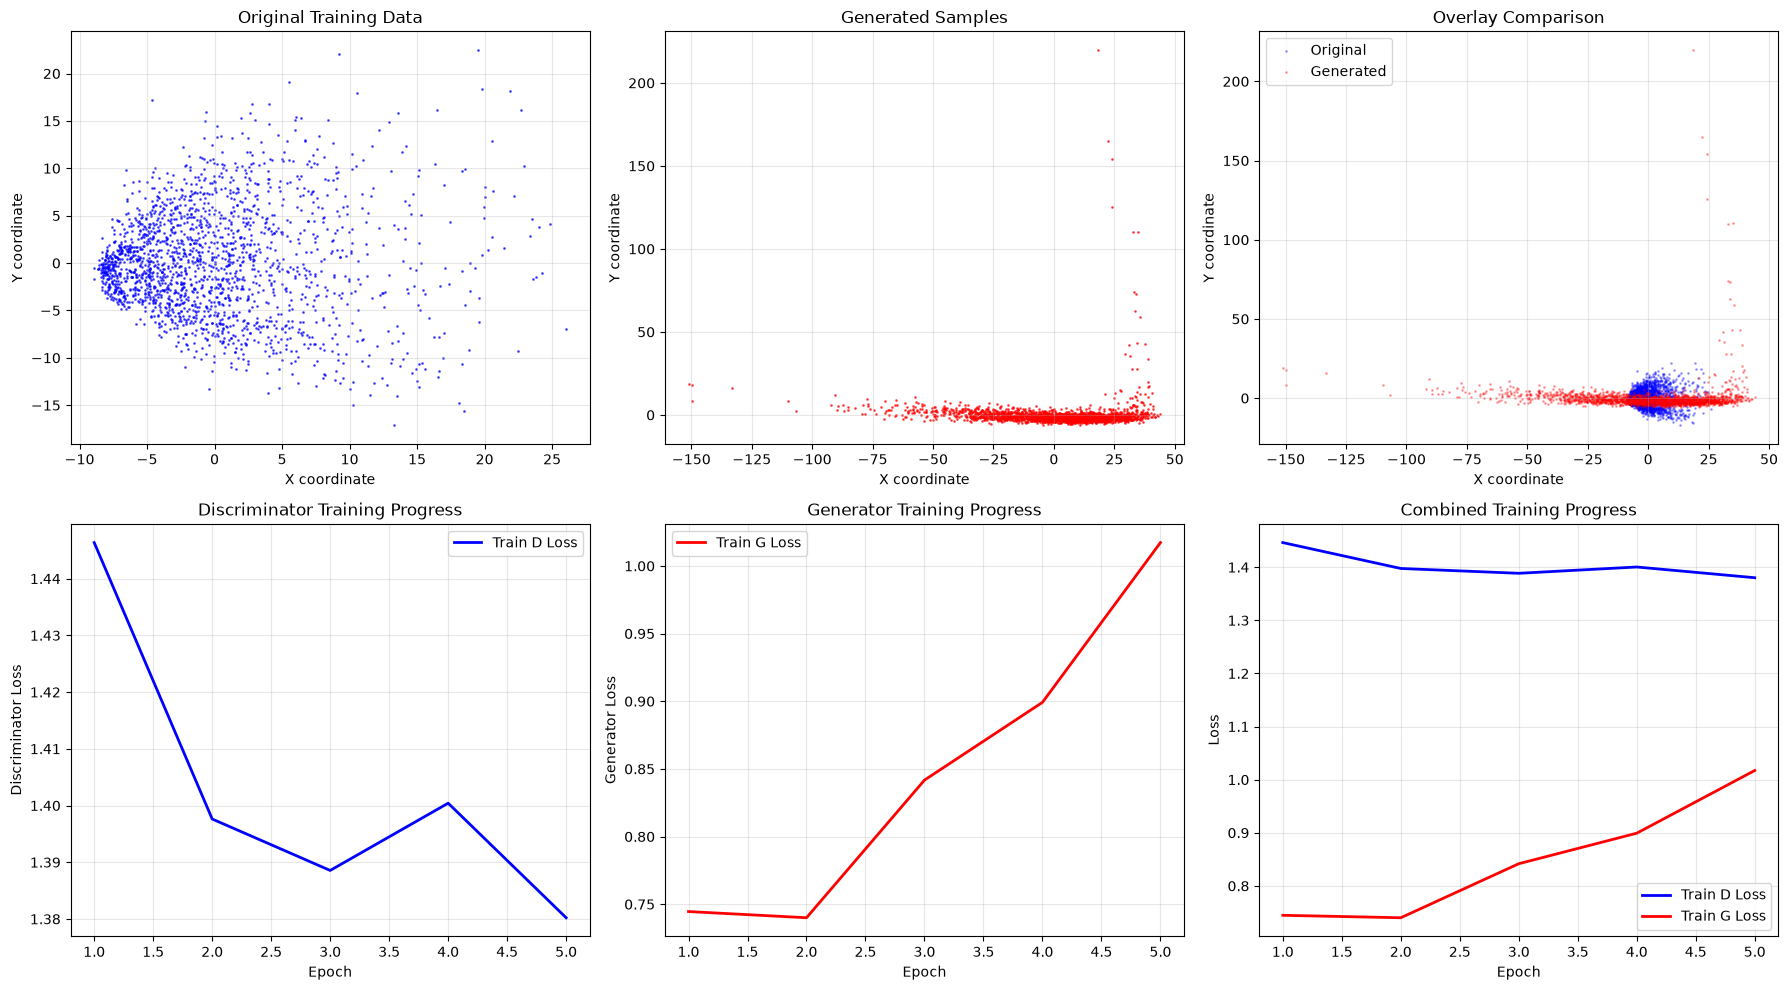

📈 Epoch 5 Summary:
   Train D Loss: 1.3802, Val D Loss: 0.9132
   Train G Loss: 1.0173, Val G Loss: 1.1615

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.928474	G_loss: 1.288728
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.553623	G_loss: 1.837546
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.087616	G_loss: 2.760194
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.438733	G_loss: 0.959803
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.778502	G_loss: 2.708741
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.987109	G_loss: 1.984829
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.725596	G_loss: 2.811987
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.815153	G_loss: 3.456563
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.010643	G_loss: 2.688503
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.850692	G_loss: 2.050518
====> Epoch: 6 Train D_loss: 1.1215, Train G_loss: 2.3457
====> Epoch: 6 Val D_loss: 1.0556, Val G_loss: 1.0767
📈 Epoch 6 Summary:
   Train D Loss: 1.1215, Val D Loss: 1.0556
   Train G Loss: 2.3457, Val G Loss: 1

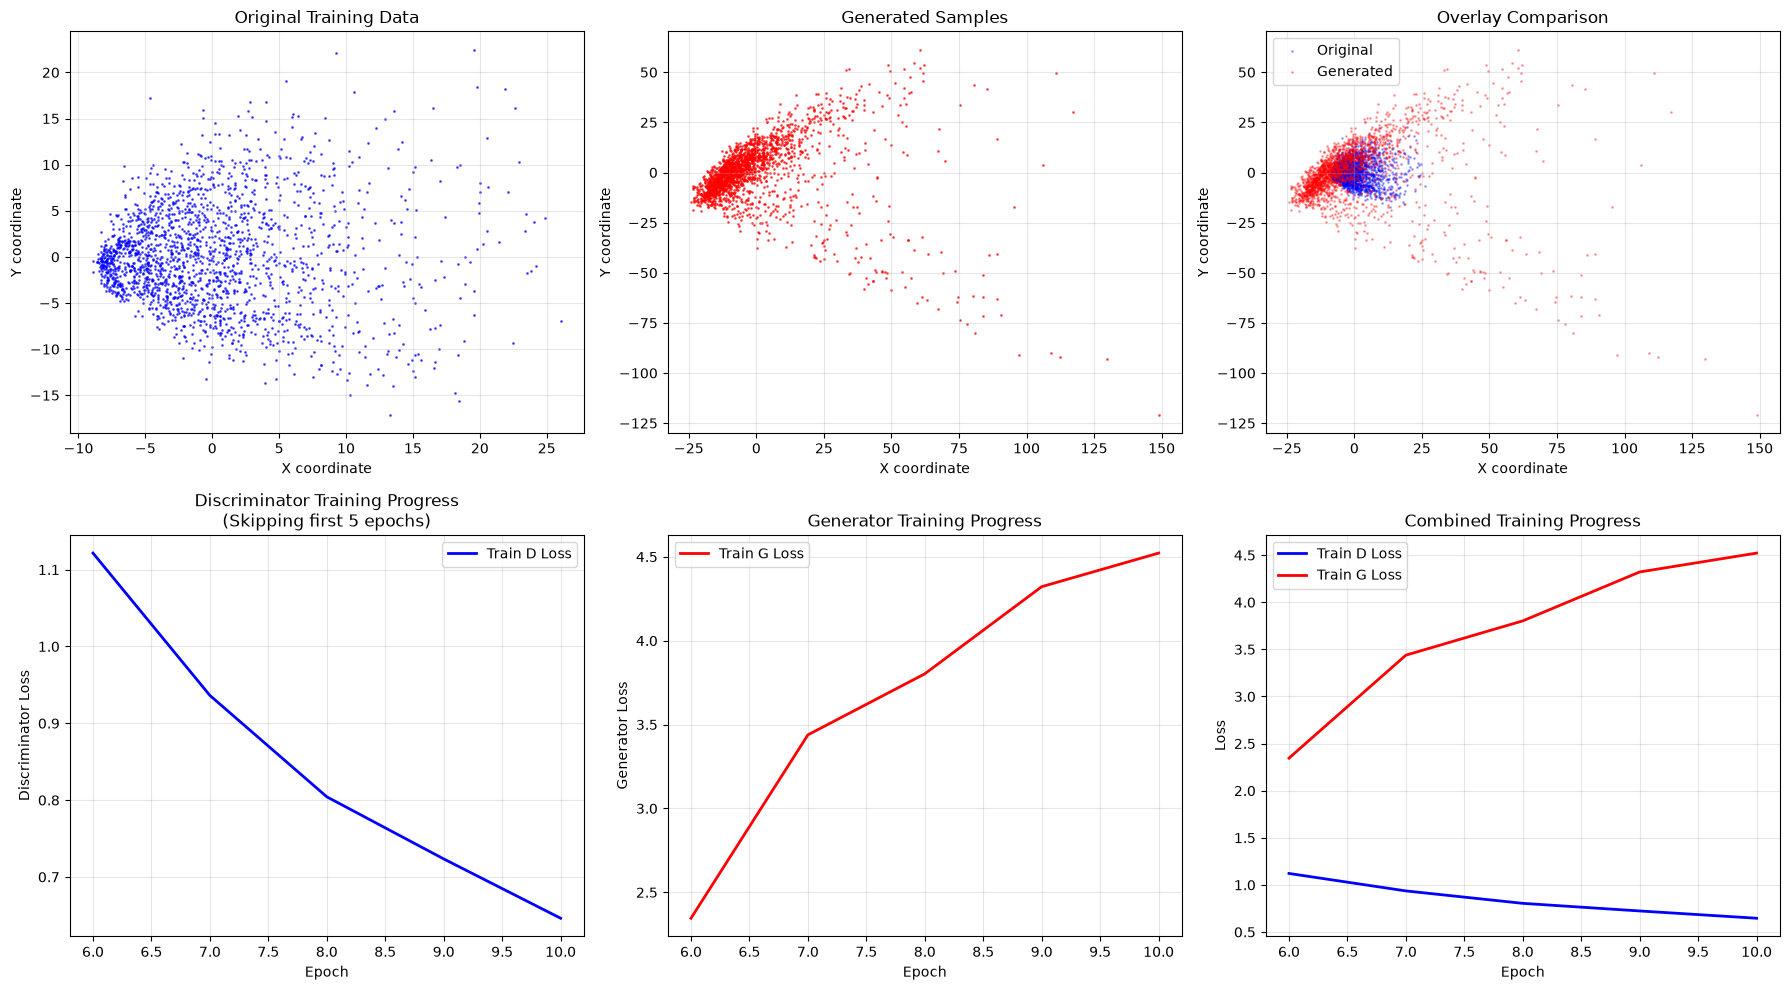

📈 Epoch 10 Summary:
   Train D Loss: 0.6462, Val D Loss: 0.3261
   Train G Loss: 4.5220, Val G Loss: 6.2641

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.409019	G_loss: 7.014724
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.411145	G_loss: 7.374643
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.677762	G_loss: 3.915621
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.372490	G_loss: 3.736995
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.738019	G_loss: 4.453233
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.300190	G_loss: 4.637423
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.507852	G_loss: 4.542128
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.497929	G_loss: 8.699800
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.248627	G_loss: 4.441213
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.755978	G_loss: 2.989072
====> Epoch: 11 Train D_loss: 0.5546, Train G_loss: 4.7828
====> Epoch: 11 Val D_loss: 0.7312, Val G_loss: 1.9873
📈 Epoch 11 Summary:
   Train D Loss: 0.5546, Val D Loss: 0.7312
   Train G Loss: 4.7828

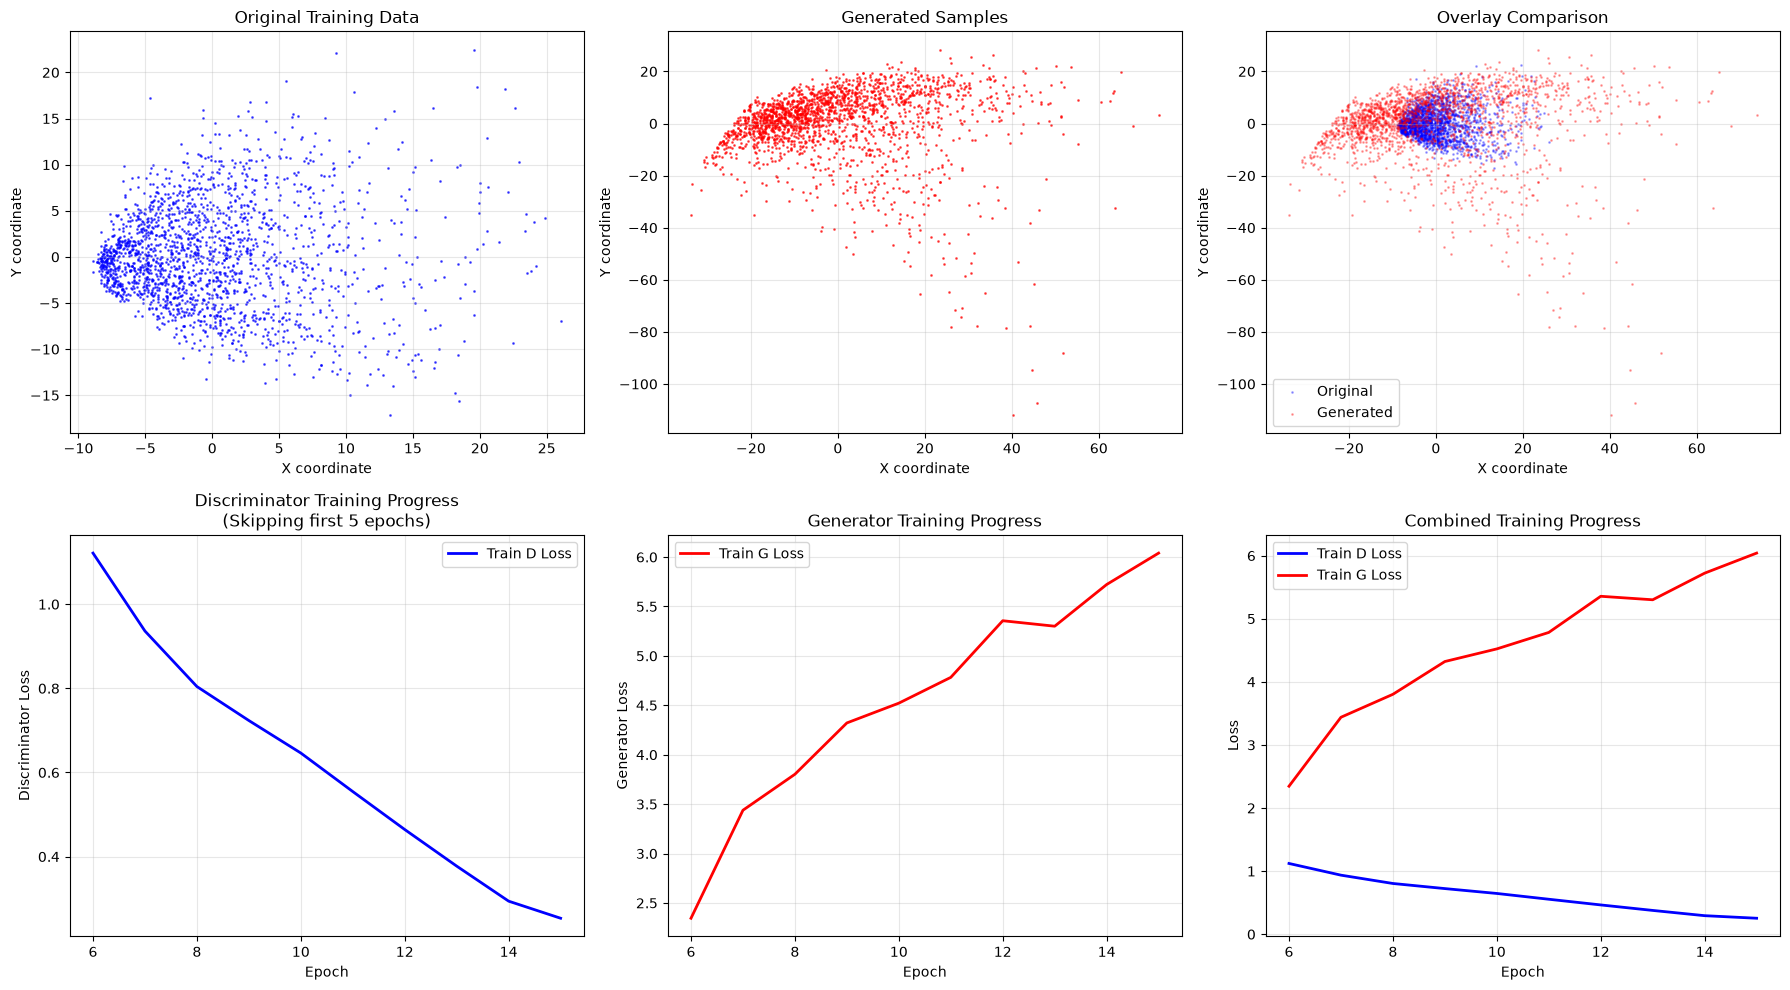

📈 Epoch 15 Summary:
   Train D Loss: 0.2535, Val D Loss: 0.2364
   Train G Loss: 6.0402, Val G Loss: 4.8942

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.117447	G_loss: 7.206072
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.278753	G_loss: 6.514243
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.155673	G_loss: 7.141719
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.226220	G_loss: 6.289070
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.094450	G_loss: 5.362803
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.187285	G_loss: 5.585250
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.153085	G_loss: 6.250823
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.196799	G_loss: 6.092251
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.233189	G_loss: 7.242043
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.199942	G_loss: 5.136348
====> Epoch: 16 Train D_loss: 0.2699, Train G_loss: 6.2342
====> Epoch: 16 Val D_loss: 0.1043, Val G_loss: 4.2657
📈 Epoch 16 Summary:
   Train D Loss: 0.2699, Val D Loss: 0.1043
   Train G Loss: 6.2342

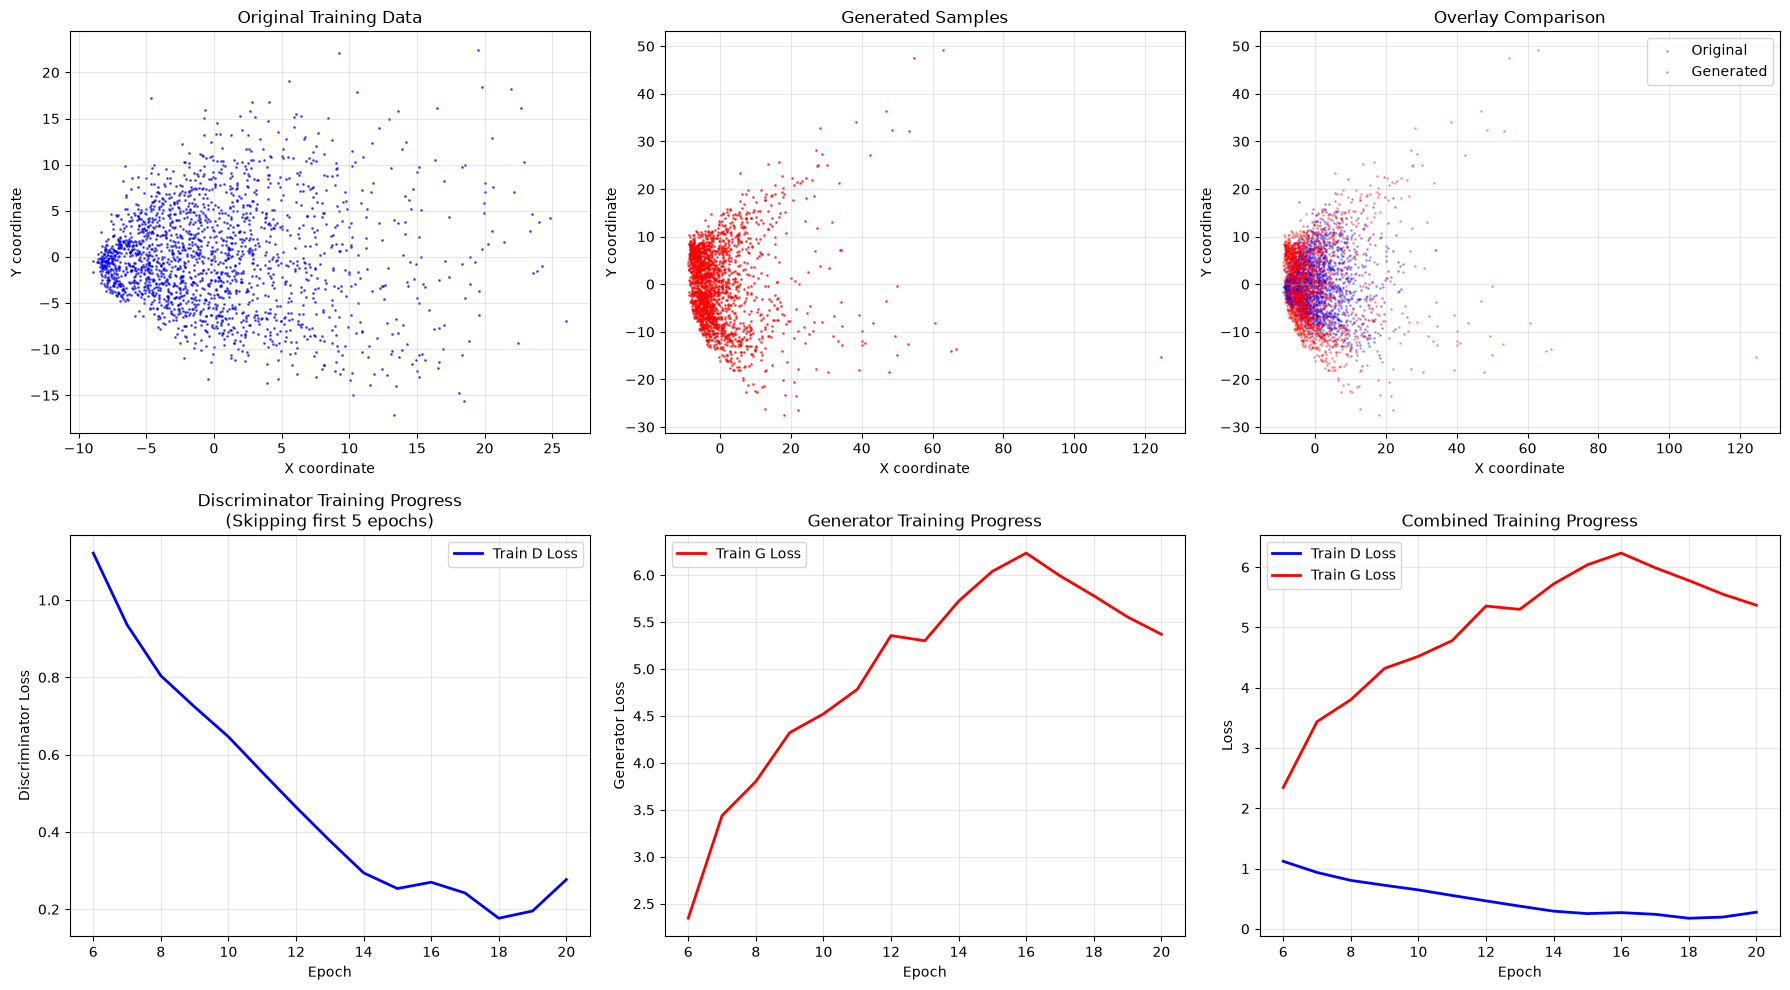

📈 Epoch 20 Summary:
   Train D Loss: 0.2767, Val D Loss: 0.1497
   Train G Loss: 5.3701, Val G Loss: 3.6955

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.156252	G_loss: 4.359973
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.272640	G_loss: 4.726630
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.429041	G_loss: 6.134413
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.163359	G_loss: 4.813418
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.584997	G_loss: 5.504415
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.314902	G_loss: 4.368711
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.208469	G_loss: 6.076683
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.597185	G_loss: 3.098444
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.238941	G_loss: 4.971085
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.263940	G_loss: 5.272636
====> Epoch: 21 Train D_loss: 0.3149, Train G_loss: 5.0983
====> Epoch: 21 Val D_loss: 0.2407, Val G_loss: 2.8882
📈 Epoch 21 Summary:
   Train D Loss: 0.3149, Val D Loss: 0.2407
   Train G Loss: 5.0983

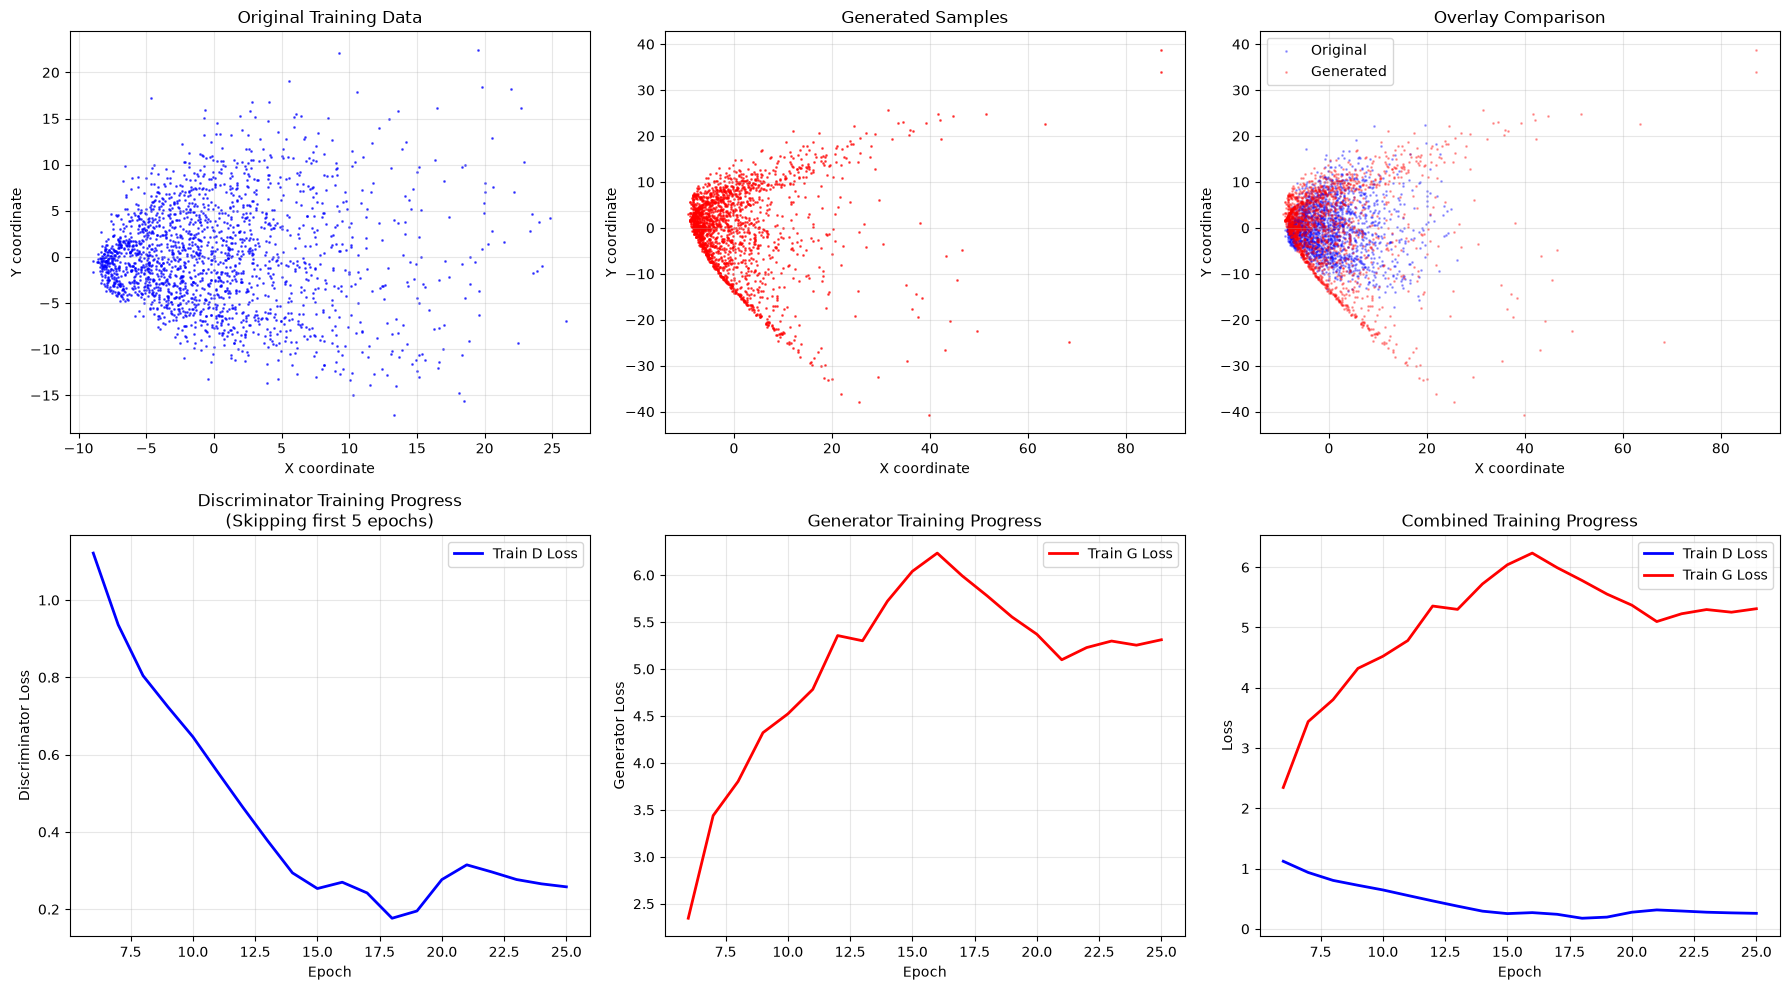

📈 Epoch 25 Summary:
   Train D Loss: 0.2579, Val D Loss: 0.2842
   Train G Loss: 5.3113, Val G Loss: 3.8251

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.313976	G_loss: 4.346546
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.165265	G_loss: 4.290955
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.178170	G_loss: 6.046287
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.264100	G_loss: 5.305682
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.125205	G_loss: 4.180826
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.073746	G_loss: 4.960511
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.080898	G_loss: 4.407383
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.165970	G_loss: 4.871473
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.107122	G_loss: 4.451173
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.198028	G_loss: 4.916685
====> Epoch: 26 Train D_loss: 0.2207, Train G_loss: 5.3423
====> Epoch: 26 Val D_loss: 0.2066, Val G_loss: 3.7887
📈 Epoch 26 Summary:
   Train D Loss: 0.2207, Val D Loss: 0.2066
   Train G Loss: 5.3423

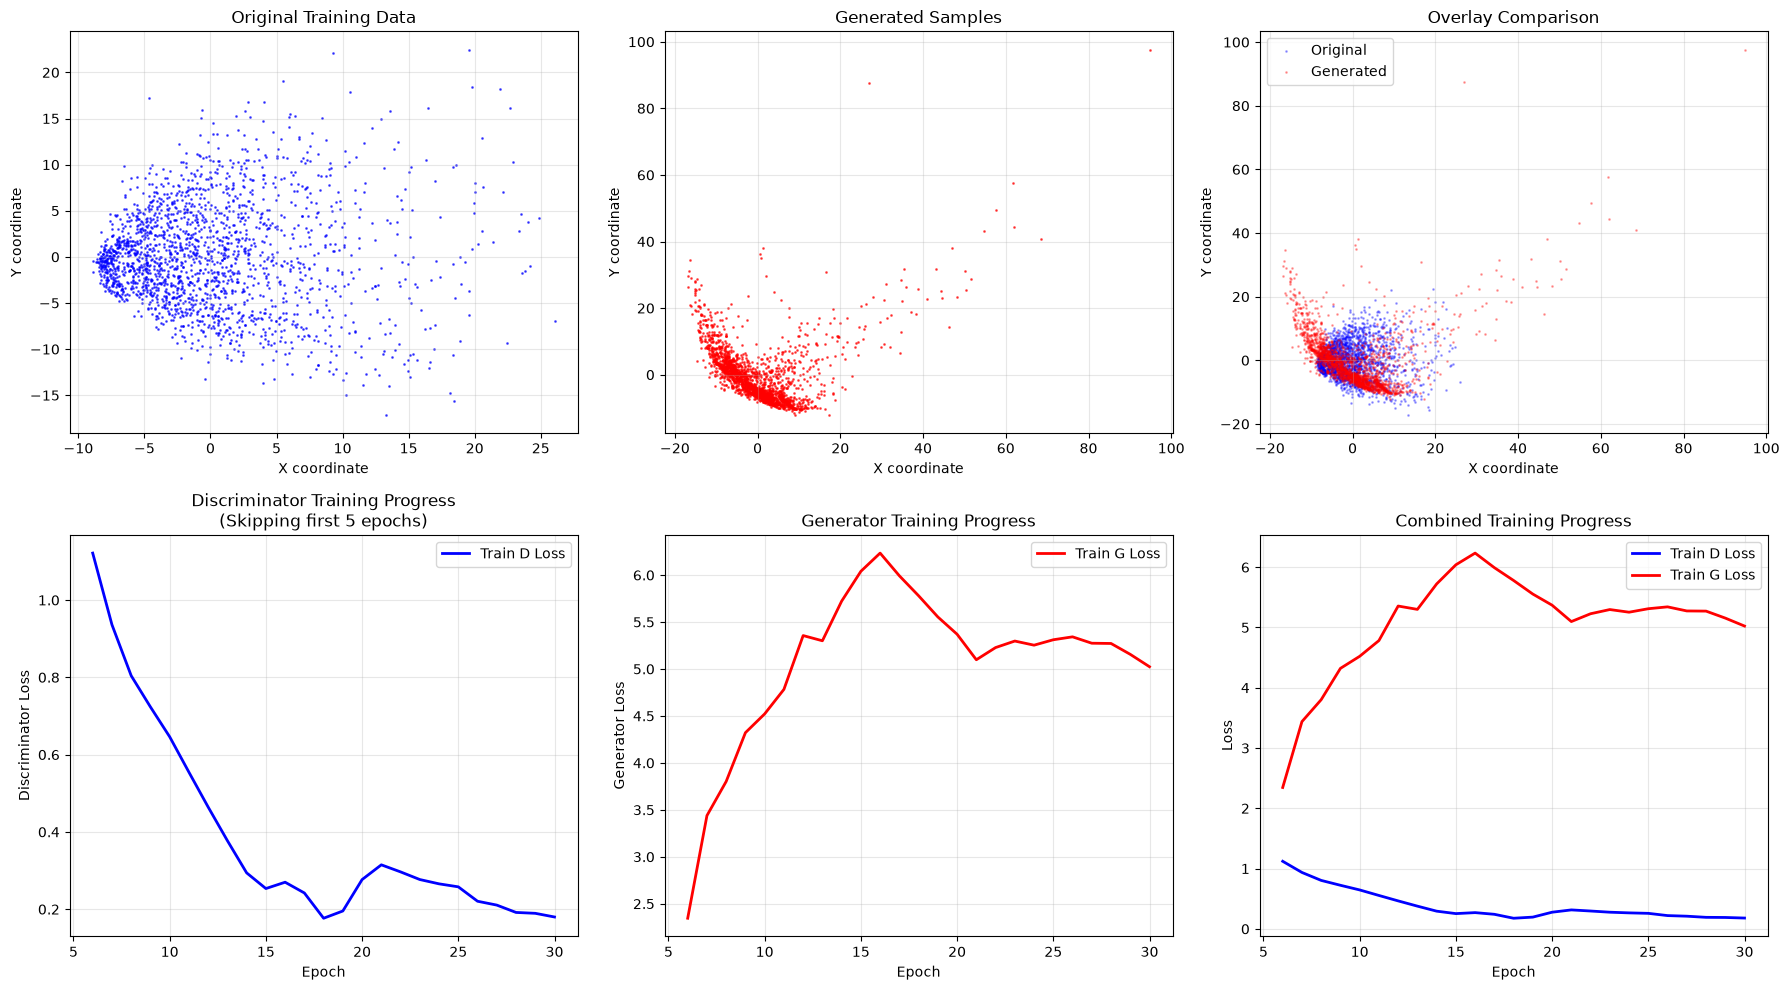

📈 Epoch 30 Summary:
   Train D Loss: 0.1799, Val D Loss: 0.1369
   Train G Loss: 5.0239, Val G Loss: 3.6728

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.134621	G_loss: 4.422156
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.101410	G_loss: 5.612822
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.056326	G_loss: 4.770937
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.211318	G_loss: 3.988039
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.188855	G_loss: 5.633790
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.231971	G_loss: 6.143750
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.268194	G_loss: 3.895245
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.133033	G_loss: 10.698662
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.172479	G_loss: 4.858141
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.257599	G_loss: 6.061203
====> Epoch: 31 Train D_loss: 0.1712, Train G_loss: 5.1547
====> Epoch: 31 Val D_loss: 0.3166, Val G_loss: 1.9315
📈 Epoch 31 Summary:
   Train D Loss: 0.1712, Val D Loss: 0.3166
   Train G Loss: 5.154

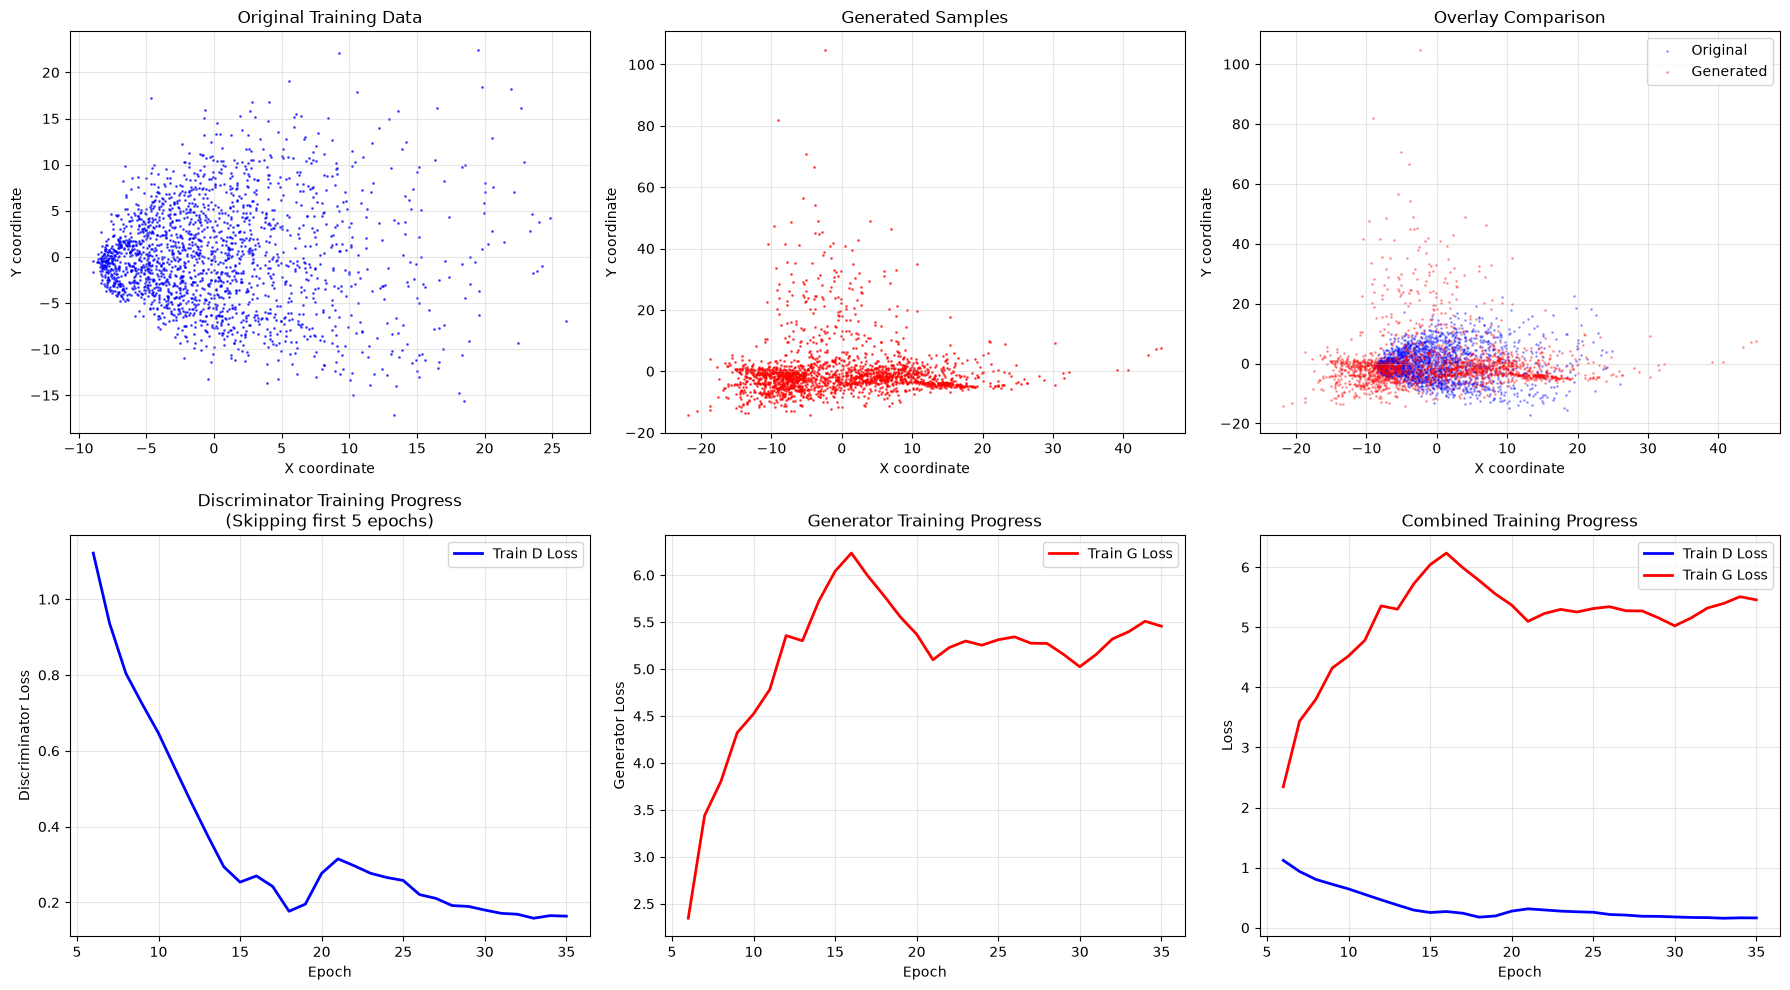

📈 Epoch 35 Summary:
   Train D Loss: 0.1638, Val D Loss: 0.1681
   Train G Loss: 5.4562, Val G Loss: 4.6025

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.126663	G_loss: 3.954669
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.710225	G_loss: 8.908369
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.059776	G_loss: 4.686131
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.040439	G_loss: 5.231460
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.142303	G_loss: 3.974832
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.147446	G_loss: 6.073993
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.200040	G_loss: 3.119824
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.121122	G_loss: 4.029347
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.113666	G_loss: 5.744070
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.324772	G_loss: 8.305233
====> Epoch: 36 Train D_loss: 0.1545, Train G_loss: 5.6478
====> Epoch: 36 Val D_loss: 0.1073, Val G_loss: 4.3848
📈 Epoch 36 Summary:
   Train D Loss: 0.1545, Val D Loss: 0.1073
   Train G Loss: 5.6478

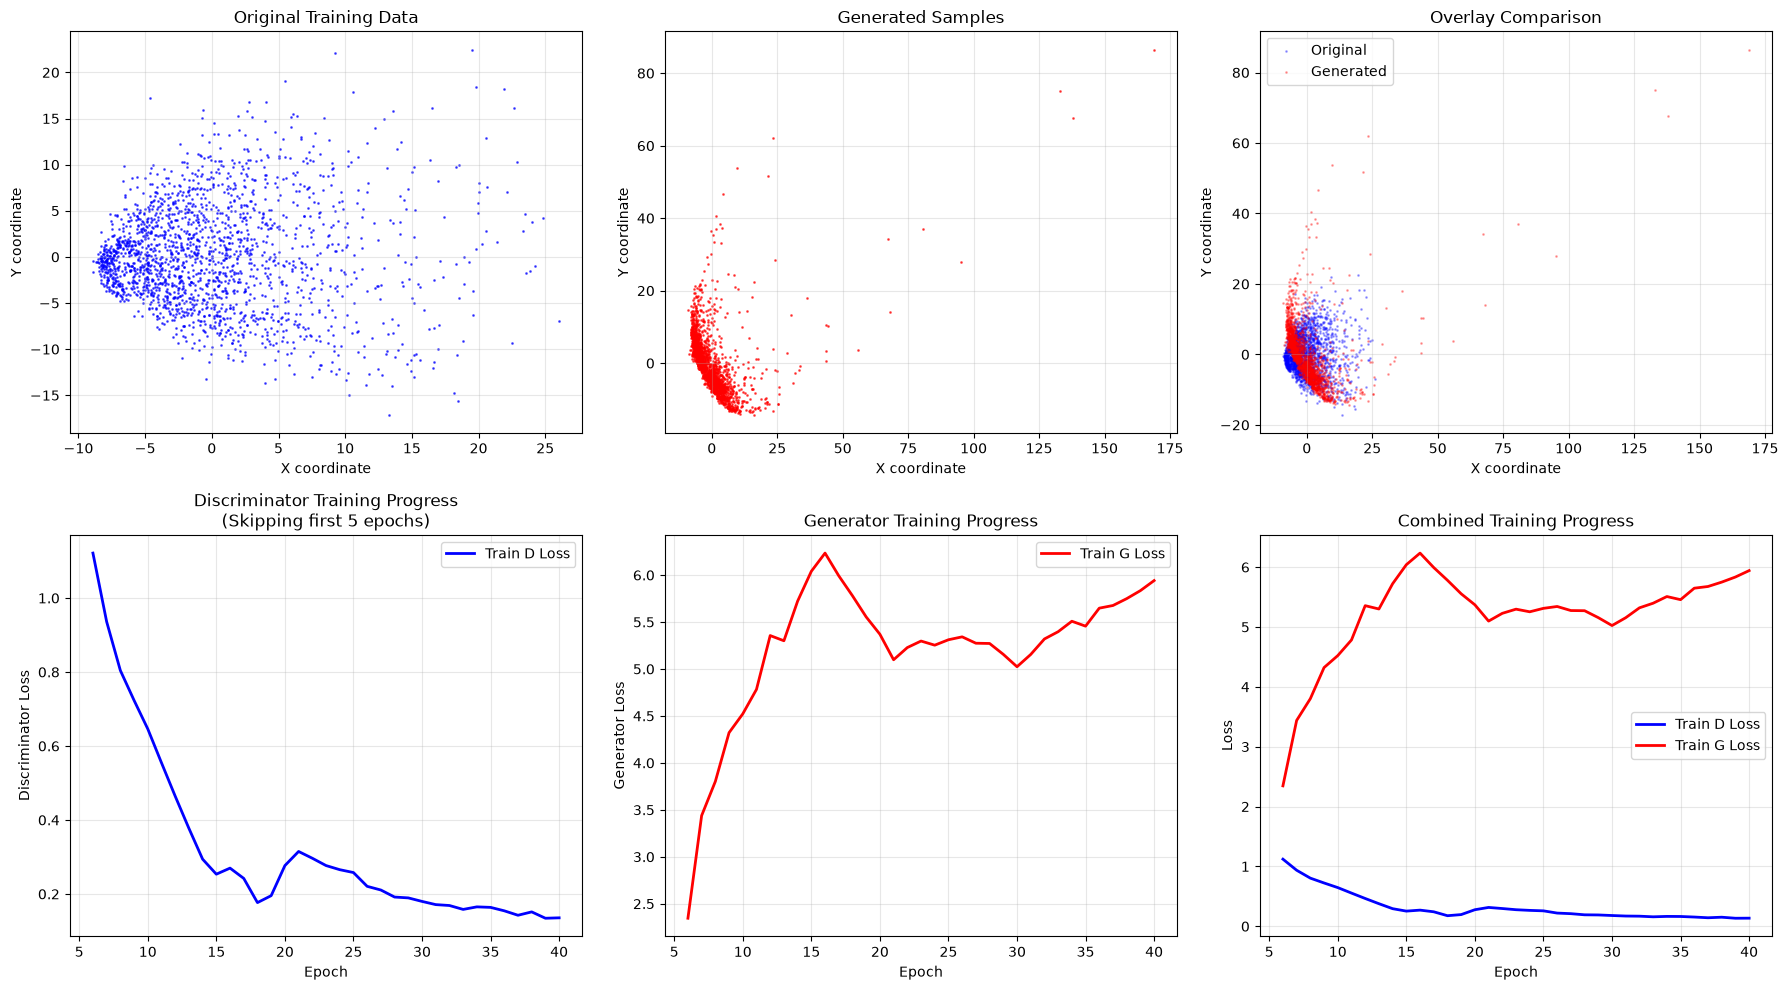

📈 Epoch 40 Summary:
   Train D Loss: 0.1355, Val D Loss: 0.0858
   Train G Loss: 5.9416, Val G Loss: 7.7429

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.047549	G_loss: 7.626130
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.138107	G_loss: 6.226188
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.087297	G_loss: 5.422909
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.251920	G_loss: 5.586444
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.073291	G_loss: 5.315331
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.132927	G_loss: 6.002732
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.080091	G_loss: 4.886413
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.073687	G_loss: 5.300654
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.057579	G_loss: 5.315742
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.556442	G_loss: 4.632286
====> Epoch: 41 Train D_loss: 0.1240, Train G_loss: 5.9519
====> Epoch: 41 Val D_loss: 0.0681, Val G_loss: 7.8197
📈 Epoch 41 Summary:
   Train D Loss: 0.1240, Val D Loss: 0.0681
   Train G Loss: 5.9519

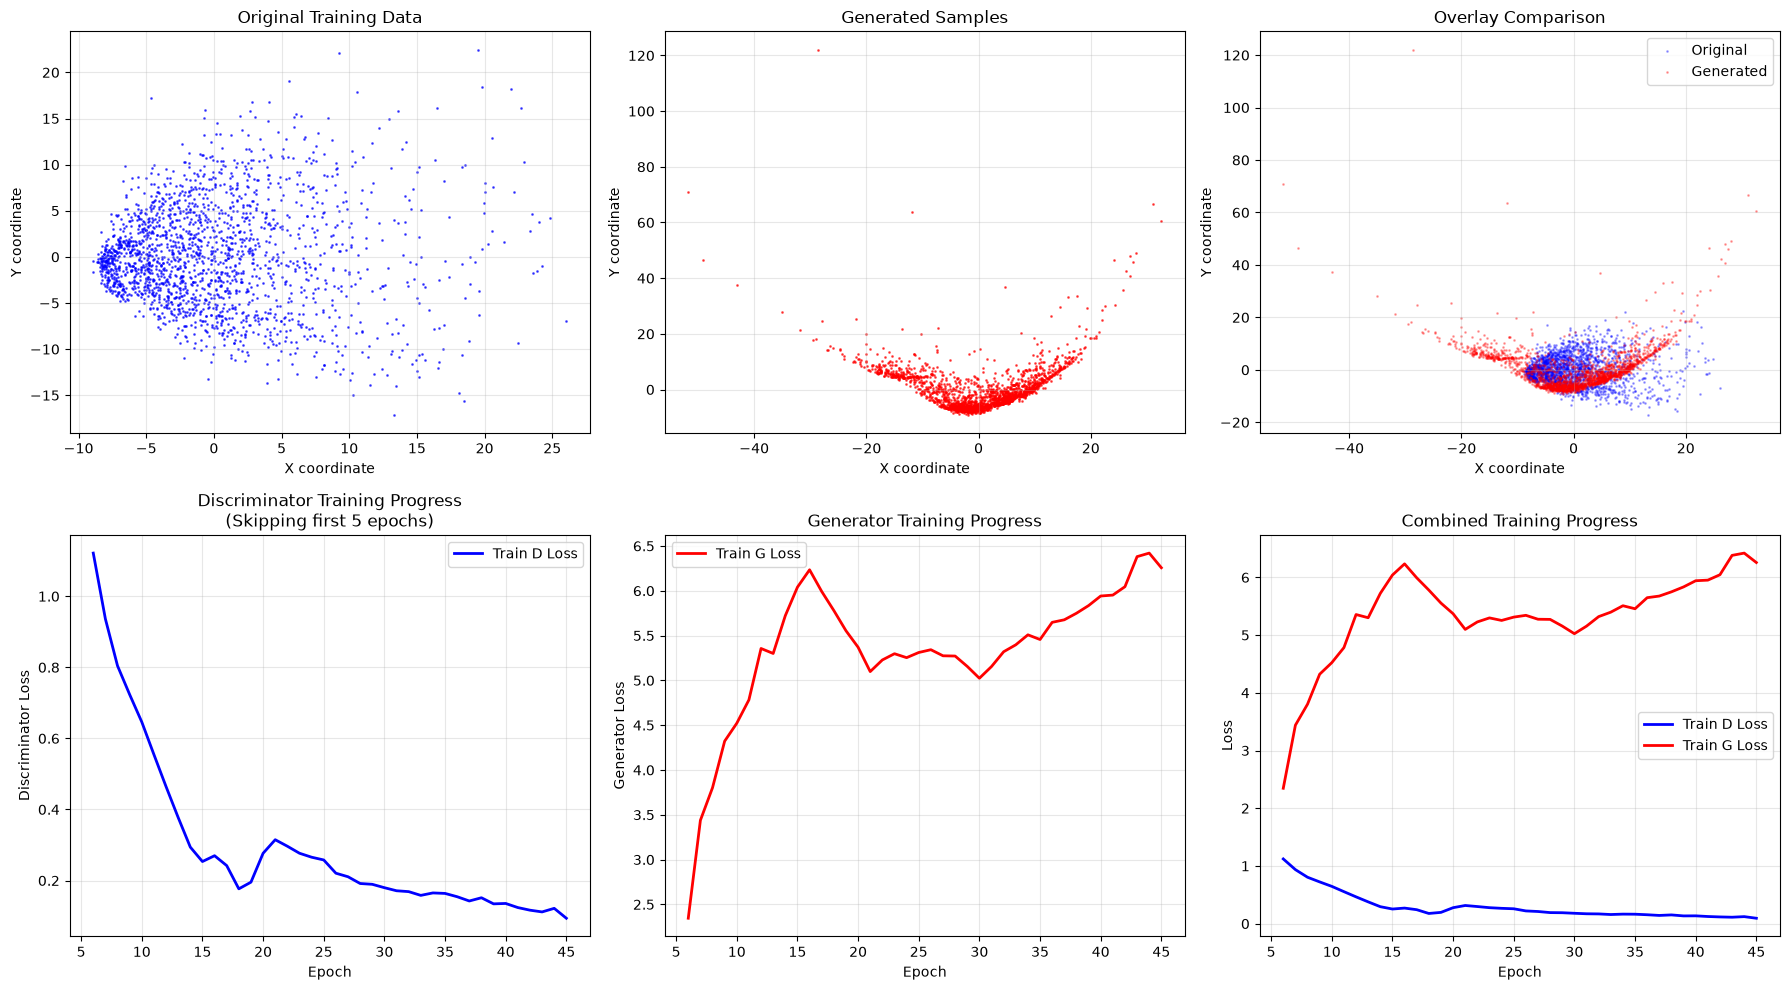

📈 Epoch 45 Summary:
   Train D Loss: 0.0939, Val D Loss: 0.1267
   Train G Loss: 6.2571, Val G Loss: 6.5262

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.100092	G_loss: 4.286216
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.197621	G_loss: 6.867192
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.068393	G_loss: 6.586419
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.135827	G_loss: 6.342080
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.099254	G_loss: 6.633264
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.031634	G_loss: 6.393555
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.074460	G_loss: 6.279028
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.040417	G_loss: 5.677392
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.213557	G_loss: 9.599262
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.085188	G_loss: 6.320969
====> Epoch: 46 Train D_loss: 0.1206, Train G_loss: 6.6425
====> Epoch: 46 Val D_loss: 0.1828, Val G_loss: 7.6831
📈 Epoch 46 Summary:
   Train D Loss: 0.1206, Val D Loss: 0.1828
   Train G Loss: 6.6425

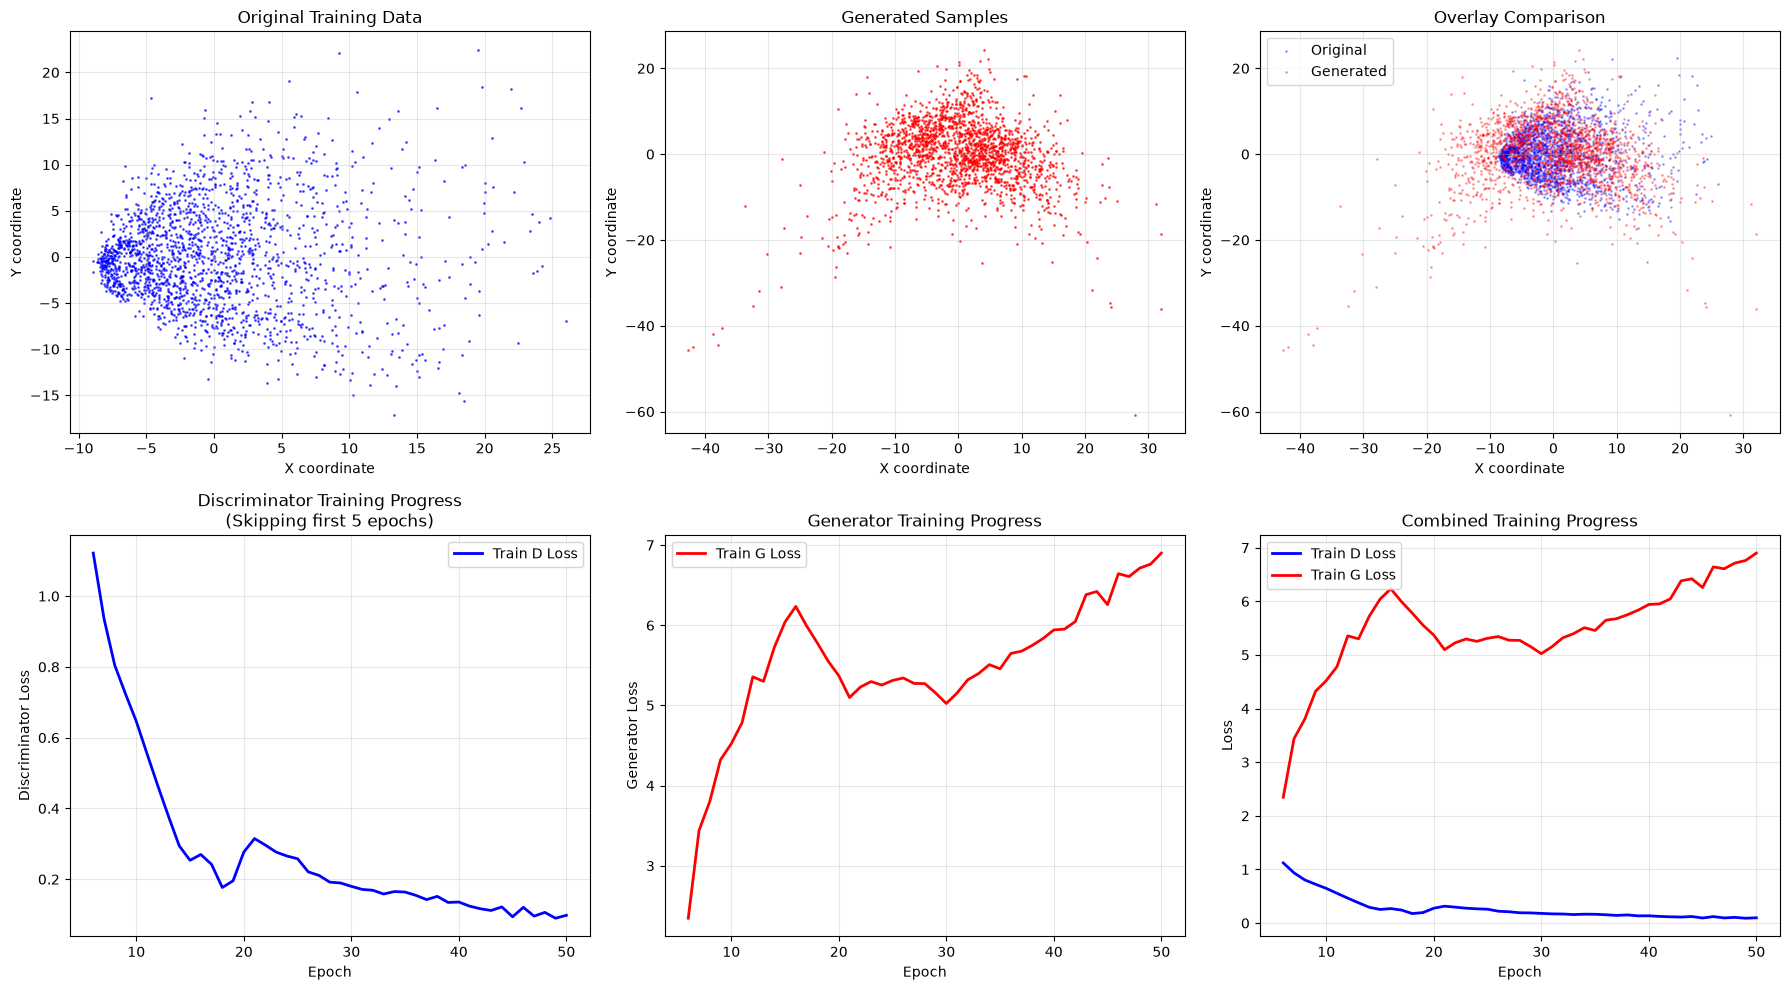

📈 Epoch 50 Summary:
   Train D Loss: 0.0981, Val D Loss: 0.0861
   Train G Loss: 6.8994, Val G Loss: 8.3763

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.112494	G_loss: 7.012005
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.047478	G_loss: 6.425874
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.050829	G_loss: 7.101089
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.107713	G_loss: 4.005351
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.231306	G_loss: 3.239136
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.034221	G_loss: 7.089893
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.011364	G_loss: 11.898691
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.061436	G_loss: 6.245128
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.048760	G_loss: 6.139568
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.191232	G_loss: 12.517087
====> Epoch: 51 Train D_loss: 0.0866, Train G_loss: 7.1454
====> Epoch: 51 Val D_loss: 0.0569, Val G_loss: 5.3544
📈 Epoch 51 Summary:
   Train D Loss: 0.0866, Val D Loss: 0.0569
   Train G Loss: 7.14

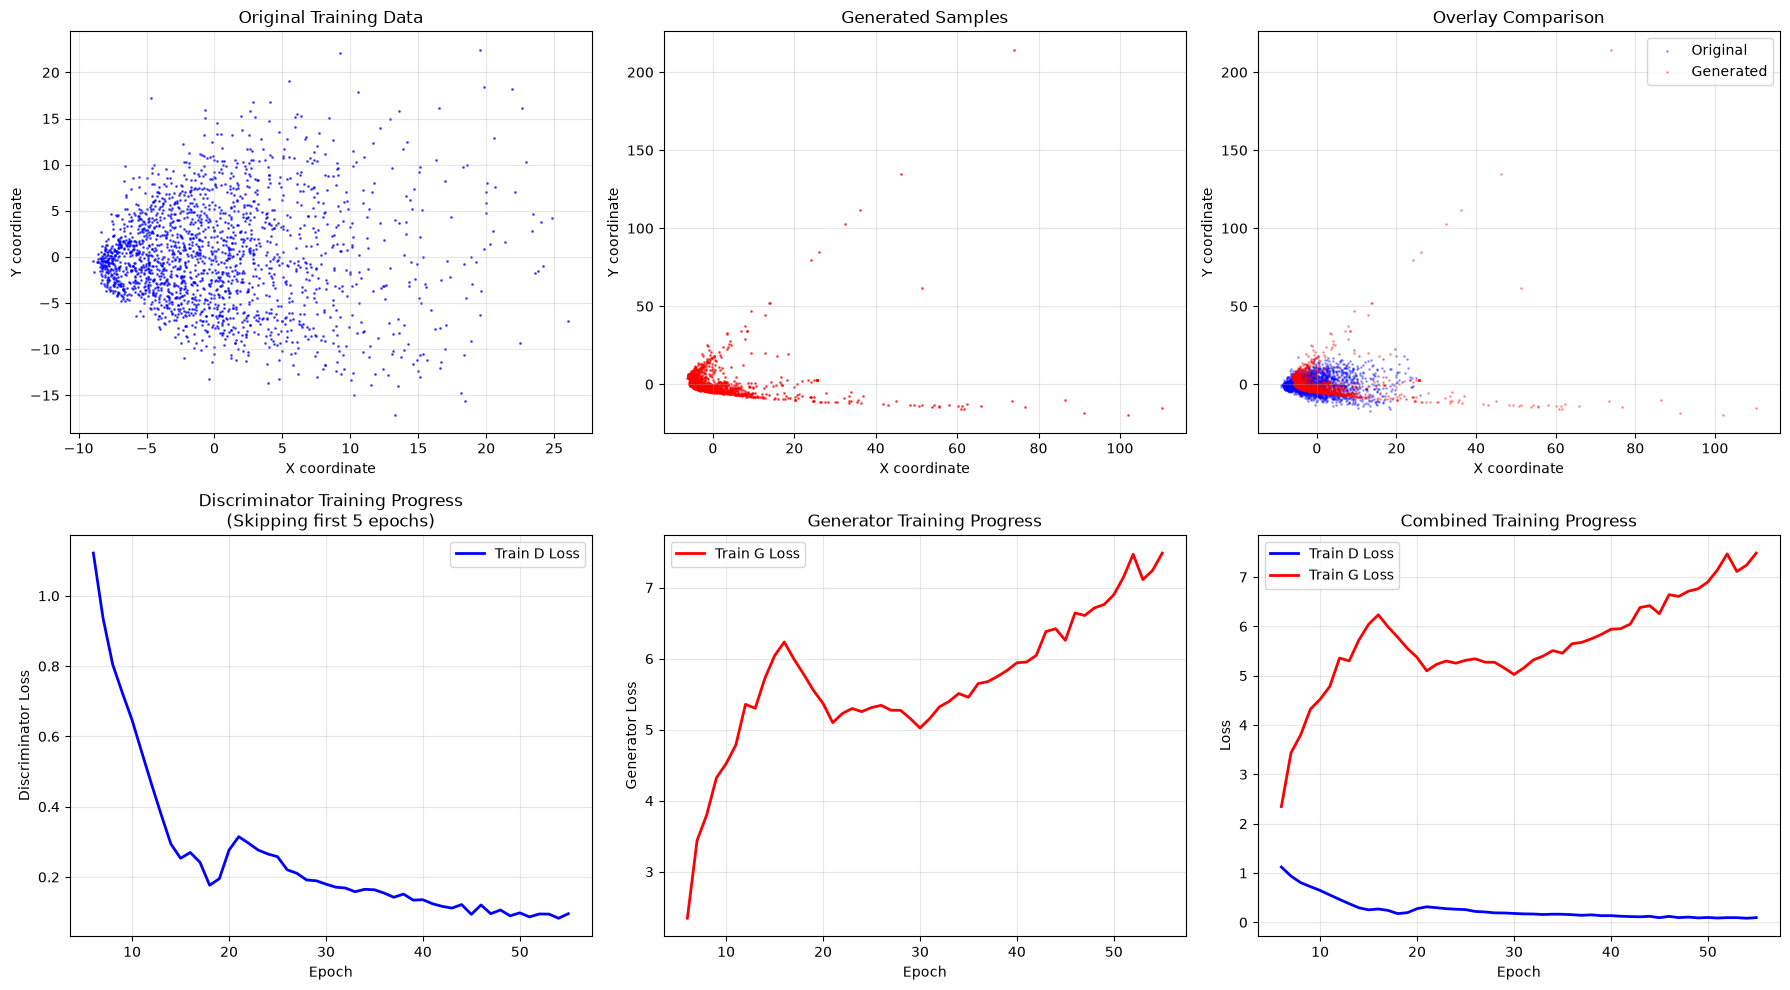

📈 Epoch 55 Summary:
   Train D Loss: 0.0957, Val D Loss: 0.1469
   Train G Loss: 7.4851, Val G Loss: 10.3561

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.158755	G_loss: 12.694941
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.060671	G_loss: 5.695290
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.116624	G_loss: 6.487539
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.045126	G_loss: 8.741241
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.061366	G_loss: 7.495183
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.106605	G_loss: 8.017368
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.054072	G_loss: 8.266508
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.064082	G_loss: 5.479958
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.105284	G_loss: 6.967557
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.013573	G_loss: 10.489515
====> Epoch: 56 Train D_loss: 0.0846, Train G_loss: 7.2574
====> Epoch: 56 Val D_loss: 0.0730, Val G_loss: 6.0769
📈 Epoch 56 Summary:
   Train D Loss: 0.0846, Val D Loss: 0.0730
   Train G Loss: 7.2

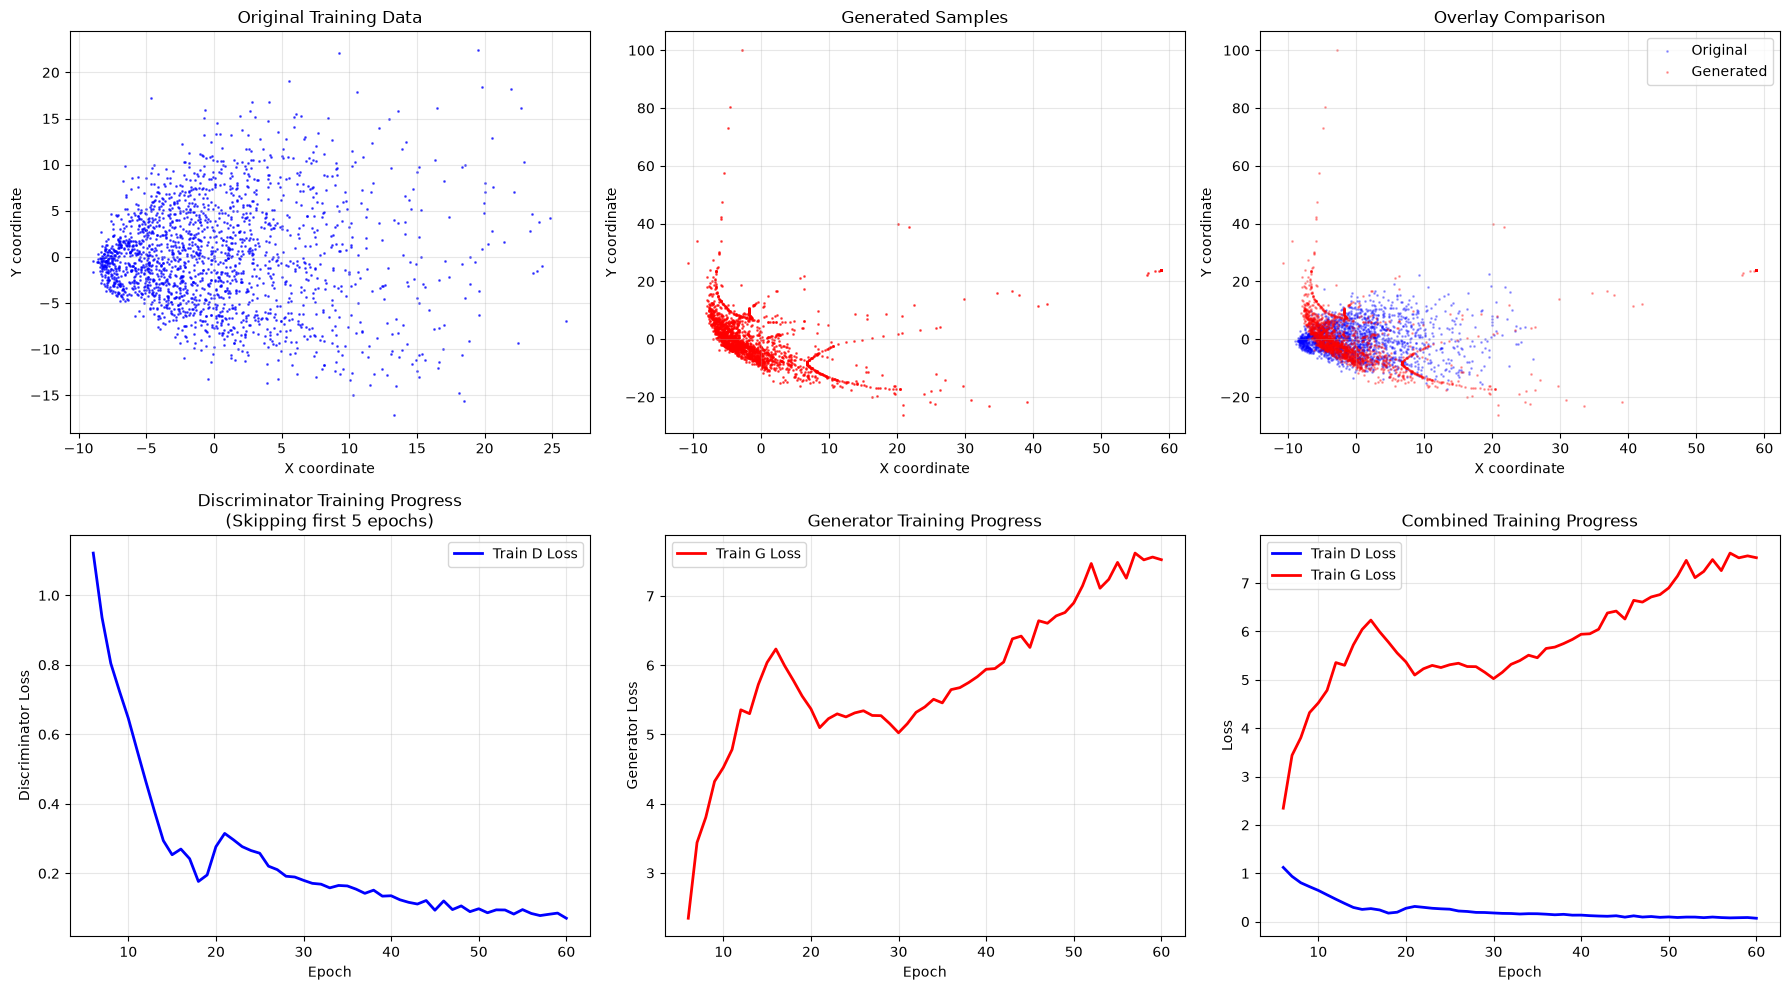

📈 Epoch 60 Summary:
   Train D Loss: 0.0708, Val D Loss: 0.2294
   Train G Loss: 7.5242, Val G Loss: 12.5877

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.152879	G_loss: 11.319414
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.146190	G_loss: 6.564949
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.025796	G_loss: 10.885389
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.053554	G_loss: 8.099201
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.046622	G_loss: 6.983559
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.141938	G_loss: 6.281582
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.054878	G_loss: 9.081682
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.140031	G_loss: 16.266977
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.034346	G_loss: 5.890681
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.010426	G_loss: 7.264910
====> Epoch: 61 Train D_loss: 0.0780, Train G_loss: 7.9108
====> Epoch: 61 Val D_loss: 0.0517, Val G_loss: 6.8544
📈 Epoch 61 Summary:
   Train D Loss: 0.0780, Val D Loss: 0.0517
   Train G Loss: 7.

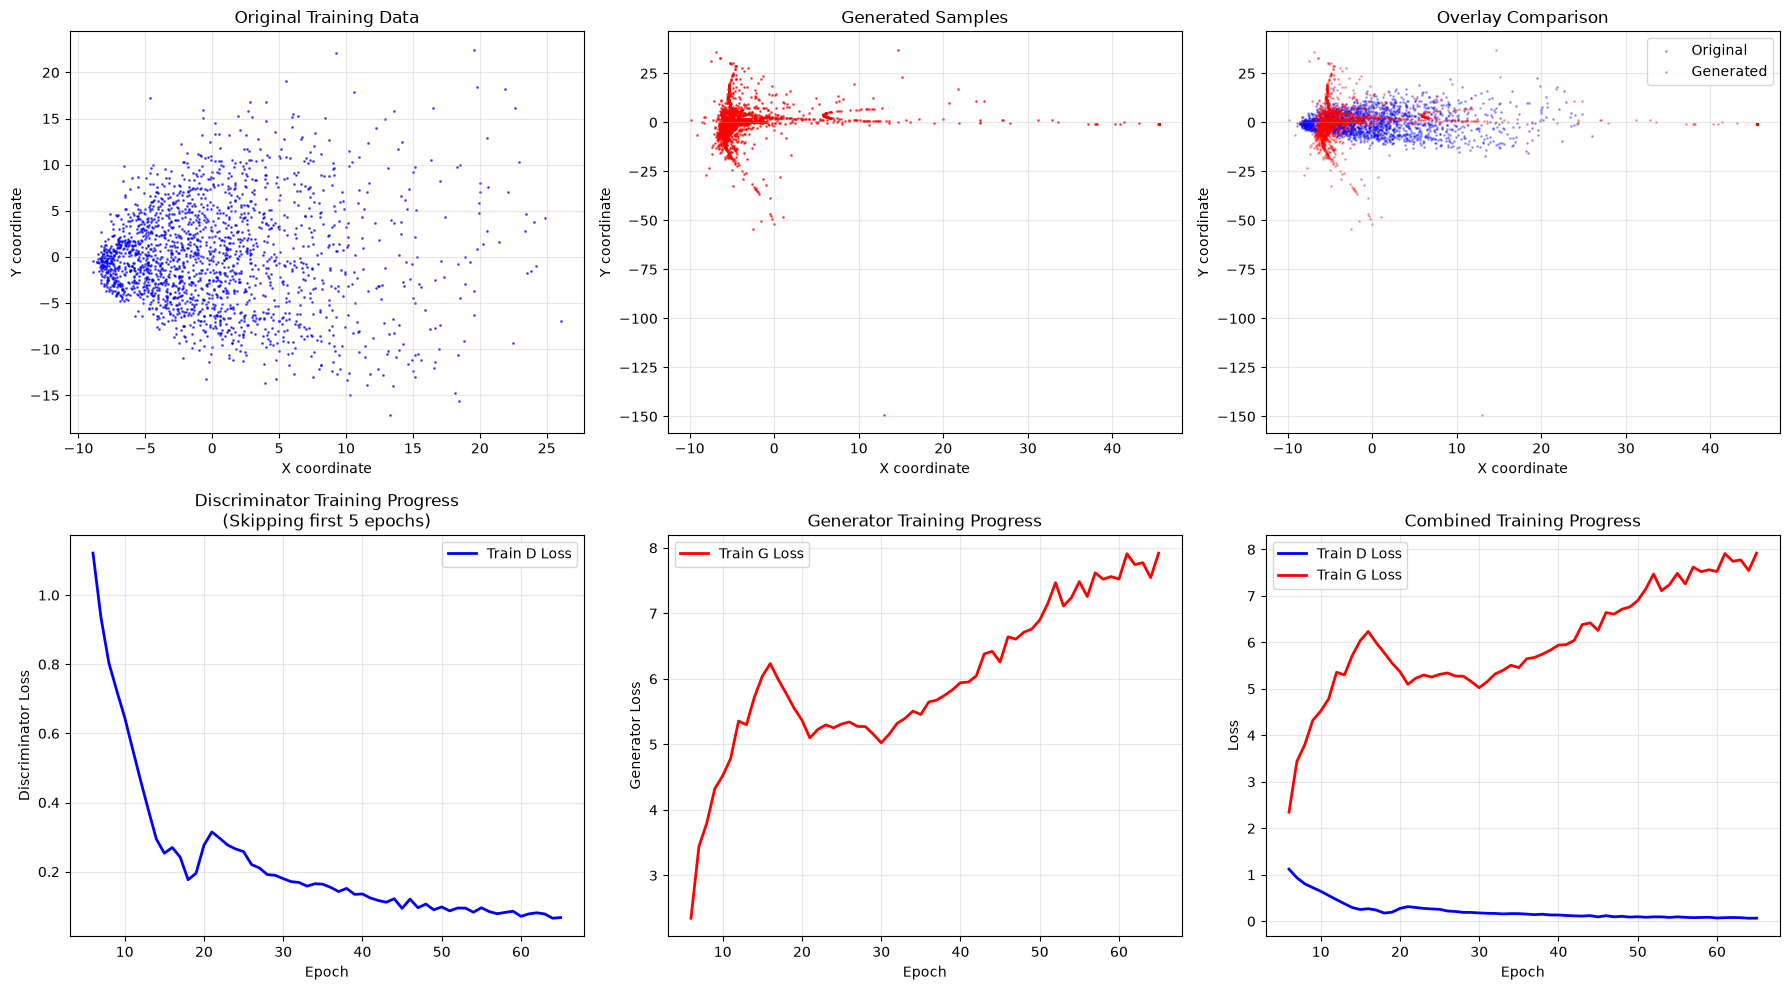

📈 Epoch 65 Summary:
   Train D Loss: 0.0673, Val D Loss: 0.2137
   Train G Loss: 7.9205, Val G Loss: 11.3001

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.161965	G_loss: 9.149006
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.019071	G_loss: 7.594498
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.033256	G_loss: 5.726387
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.035450	G_loss: 6.888376
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.049543	G_loss: 7.326794
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.192386	G_loss: 11.251534
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.080115	G_loss: 6.904161
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.020394	G_loss: 9.537387
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.093438	G_loss: 8.139384
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.042619	G_loss: 7.145549
====> Epoch: 66 Train D_loss: 0.0626, Train G_loss: 7.8276
====> Epoch: 66 Val D_loss: 0.0372, Val G_loss: 7.9798
📈 Epoch 66 Summary:
   Train D Loss: 0.0626, Val D Loss: 0.0372
   Train G Loss: 7.82

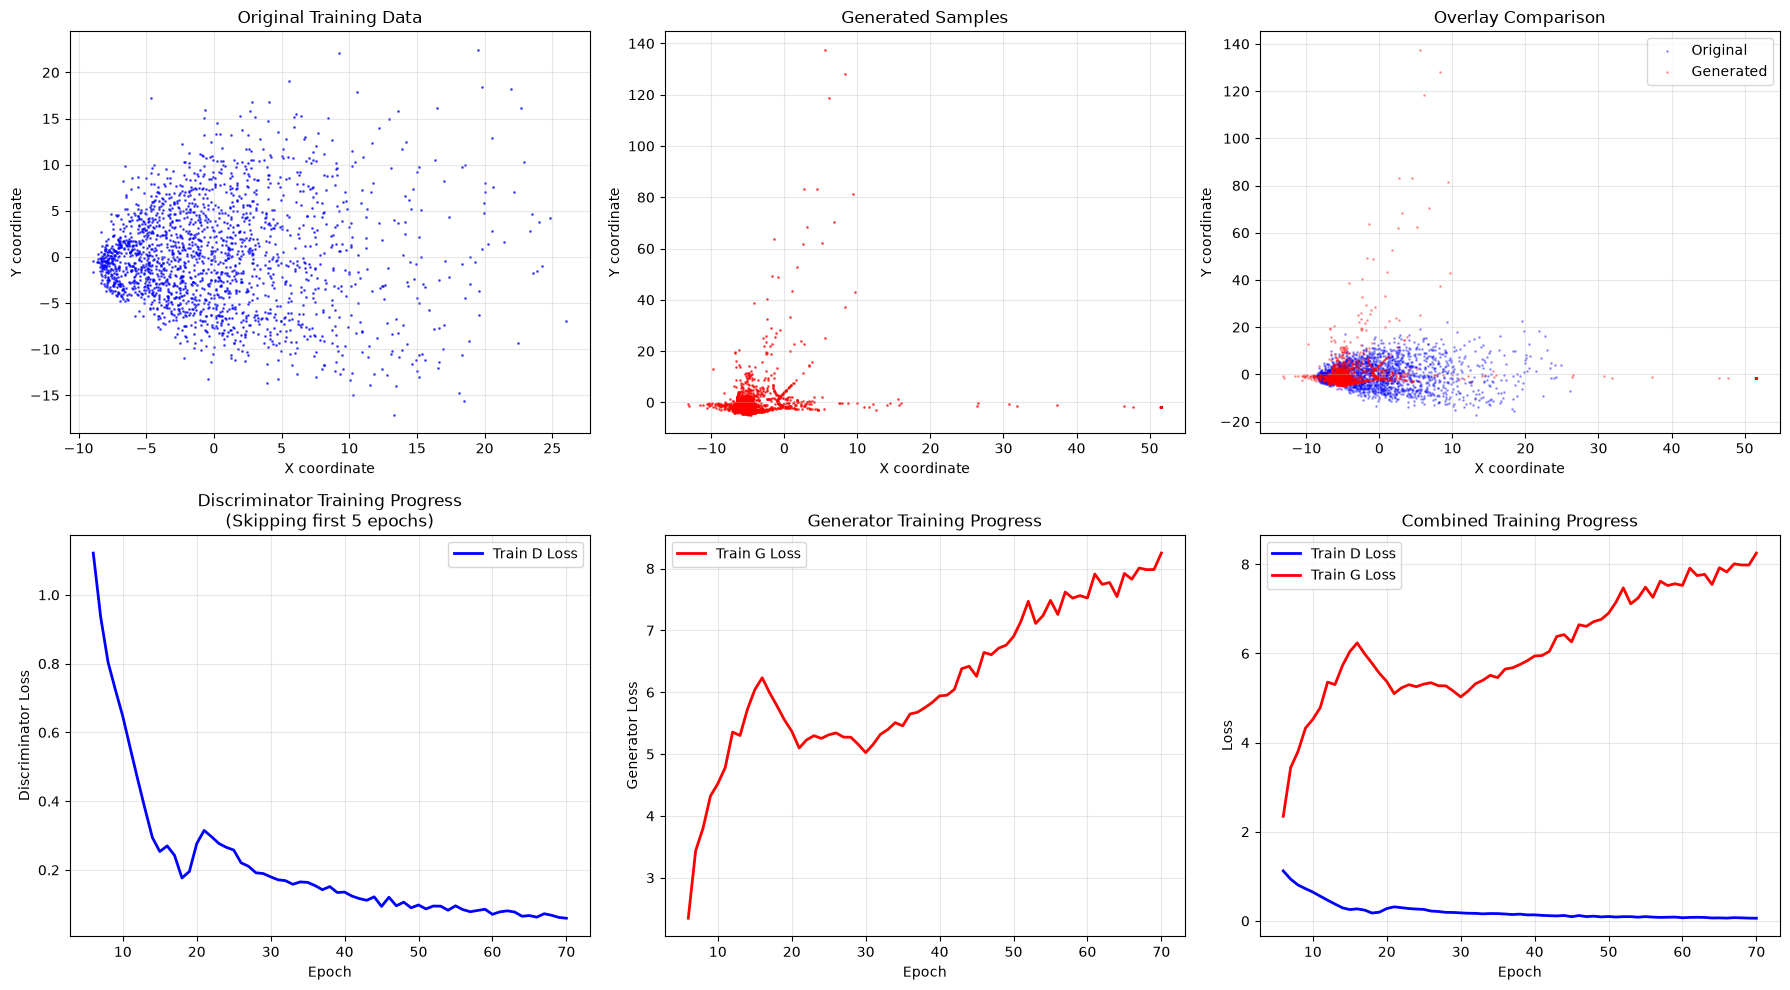

📈 Epoch 70 Summary:
   Train D Loss: 0.0595, Val D Loss: 0.0393
   Train G Loss: 8.2496, Val G Loss: 7.5497

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.018117	G_loss: 7.476182
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.032036	G_loss: 7.077477
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.022354	G_loss: 6.432580
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.022185	G_loss: 8.446124
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.048581	G_loss: 9.894821
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.012131	G_loss: 6.672107
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.178178	G_loss: 9.961353
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.044741	G_loss: 7.457044
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.046611	G_loss: 6.313838
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.000527	G_loss: 10.227114
====> Epoch: 71 Train D_loss: 0.0599, Train G_loss: 7.9438
====> Epoch: 71 Val D_loss: 0.0652, Val G_loss: 6.0841
📈 Epoch 71 Summary:
   Train D Loss: 0.0599, Val D Loss: 0.0652
   Train G Loss: 7.943

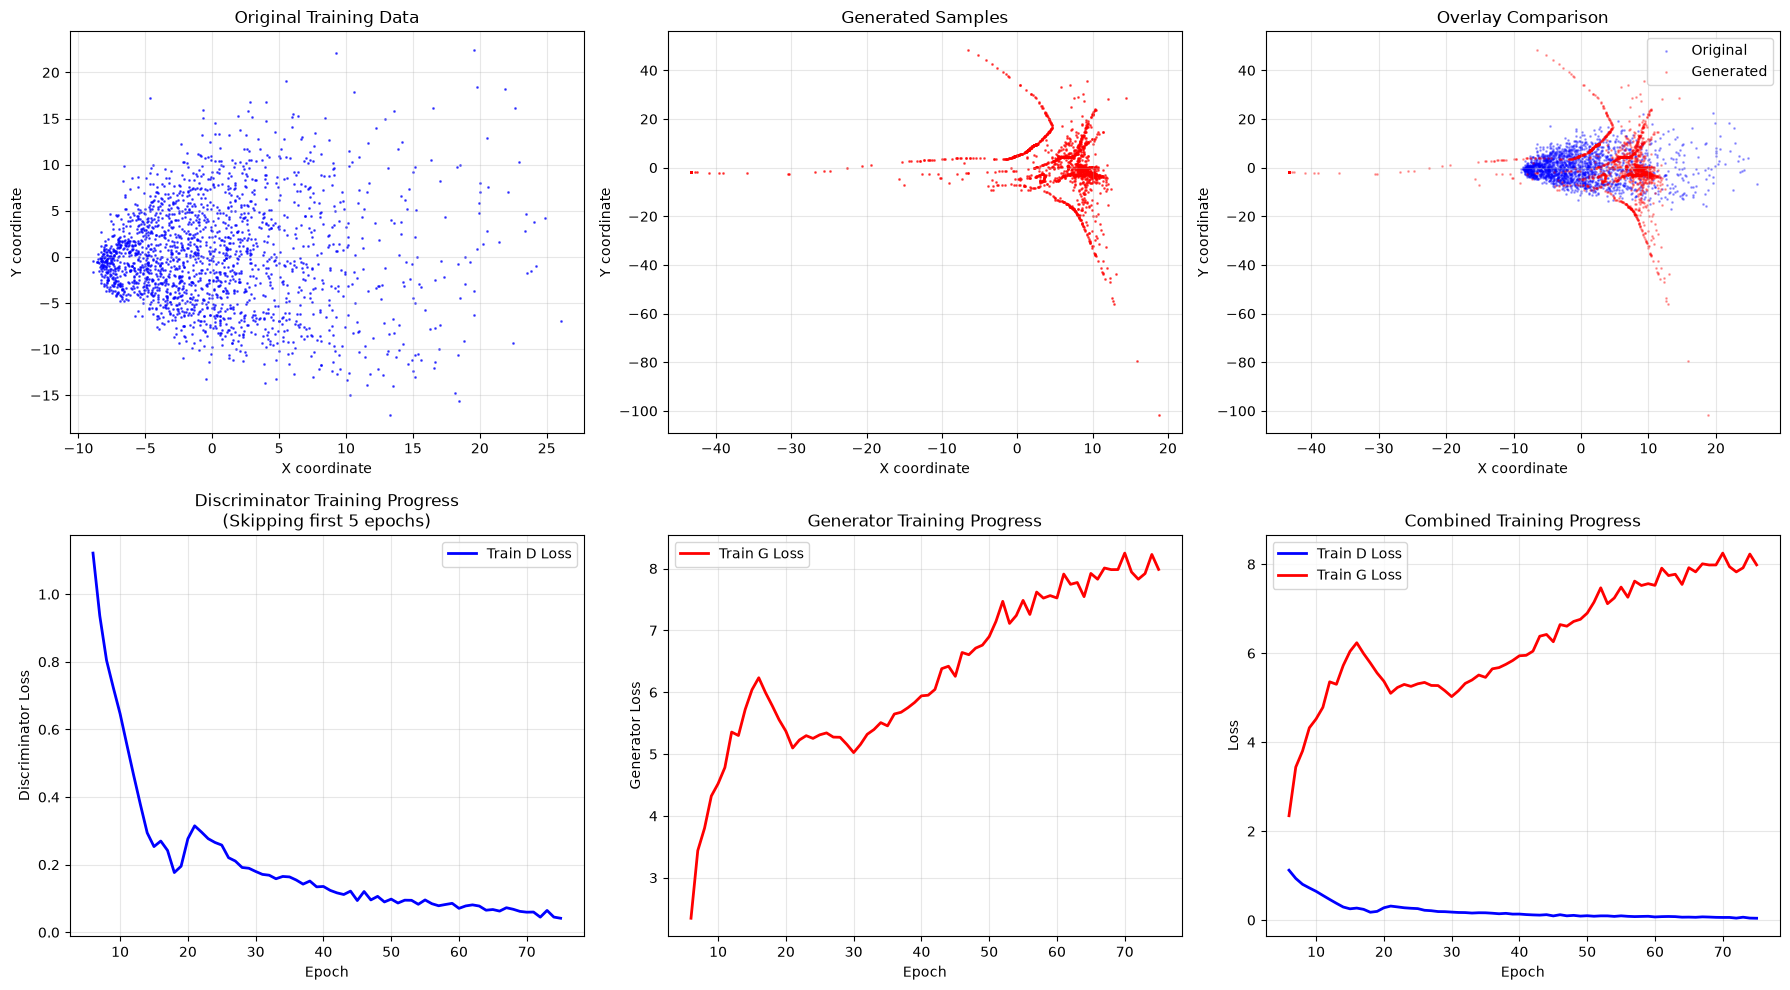

📈 Epoch 75 Summary:
   Train D Loss: 0.0415, Val D Loss: 0.0284
   Train G Loss: 7.9854, Val G Loss: 8.0468

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.007312	G_loss: 8.153751
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.023684	G_loss: 8.093800
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.052916	G_loss: 6.589611
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.039162	G_loss: 7.571384
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.043351	G_loss: 6.119030
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.041631	G_loss: 4.989030
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.019973	G_loss: 8.889383
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.039945	G_loss: 8.062778
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.083110	G_loss: 7.712282
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.030850	G_loss: 6.497470
====> Epoch: 76 Train D_loss: 0.0367, Train G_loss: 8.0778
====> Epoch: 76 Val D_loss: 0.0386, Val G_loss: 8.0322
📈 Epoch 76 Summary:
   Train D Loss: 0.0367, Val D Loss: 0.0386
   Train G Loss: 8.0778

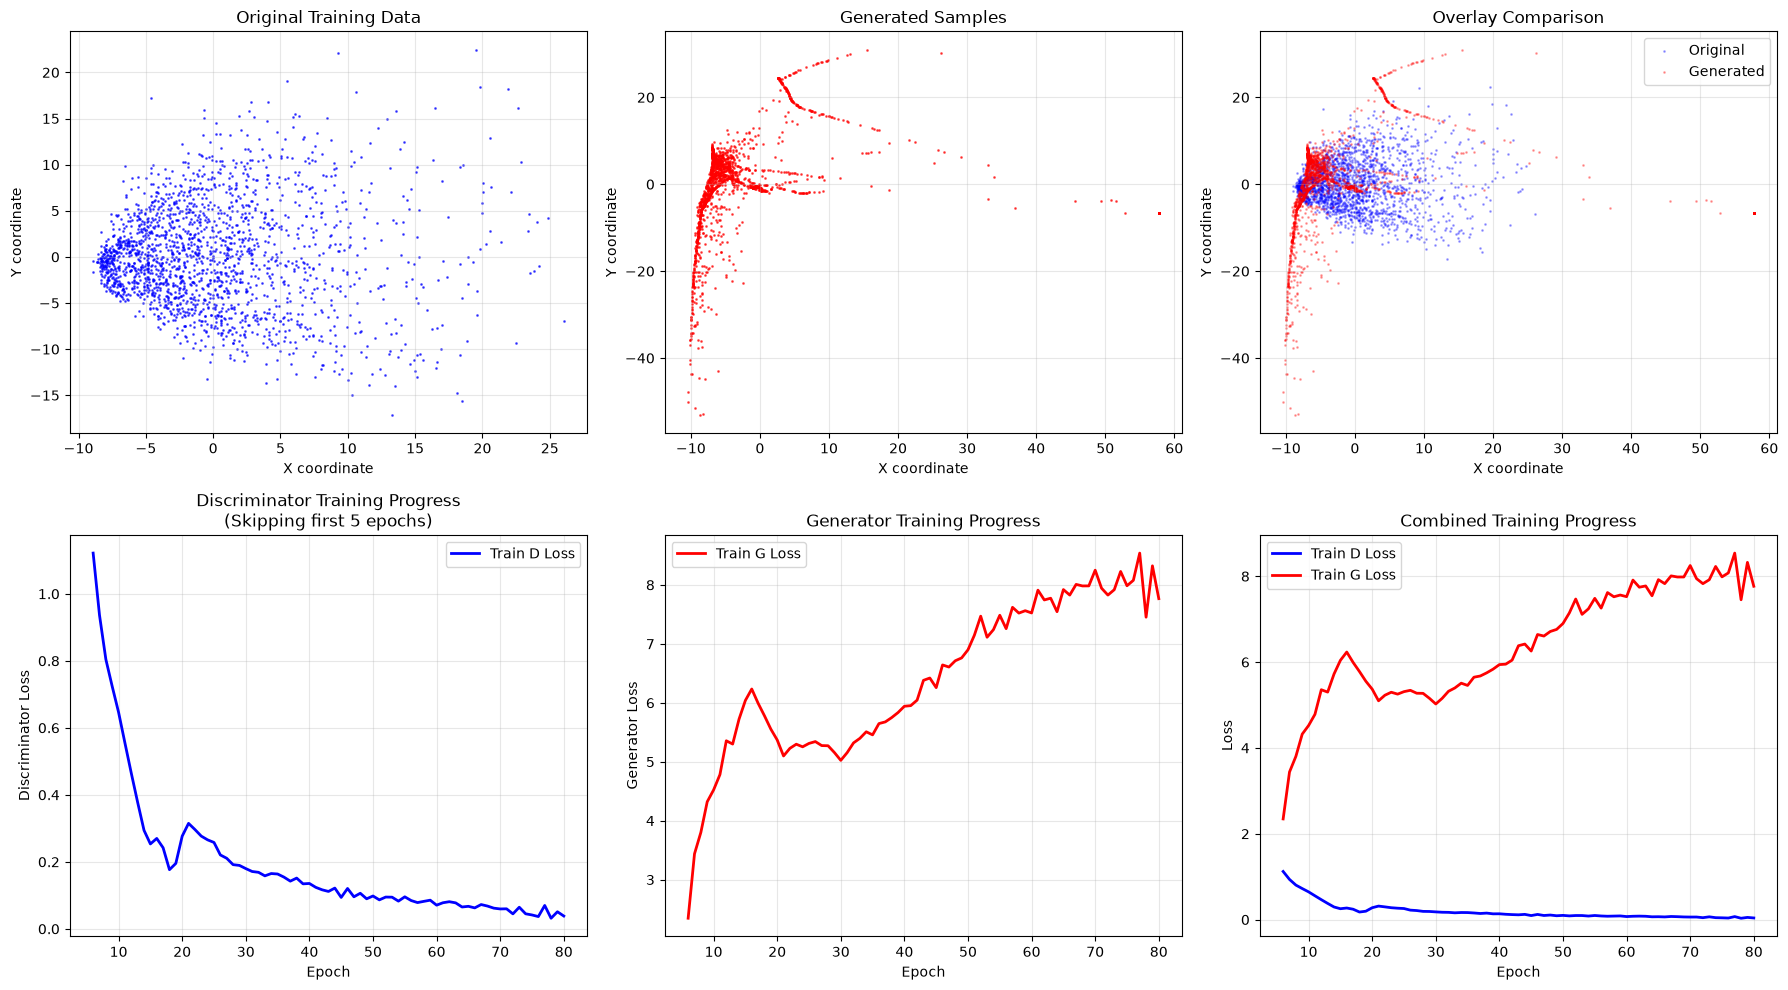

📈 Epoch 80 Summary:
   Train D Loss: 0.0383, Val D Loss: 0.0281
   Train G Loss: 7.7668, Val G Loss: 7.0920

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.004631	G_loss: 7.452329
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.006636	G_loss: 7.990434
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.024106	G_loss: 5.612863
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.034201	G_loss: 8.862856
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.033552	G_loss: 8.157291
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.073235	G_loss: 11.194692
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.019112	G_loss: 5.902829
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.036374	G_loss: 7.869111
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.020593	G_loss: 6.844897
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.045997	G_loss: 6.808625
====> Epoch: 81 Train D_loss: 0.0377, Train G_loss: 8.6032
====> Epoch: 81 Val D_loss: 0.0826, Val G_loss: 8.4597
📈 Epoch 81 Summary:
   Train D Loss: 0.0377, Val D Loss: 0.0826
   Train G Loss: 8.603

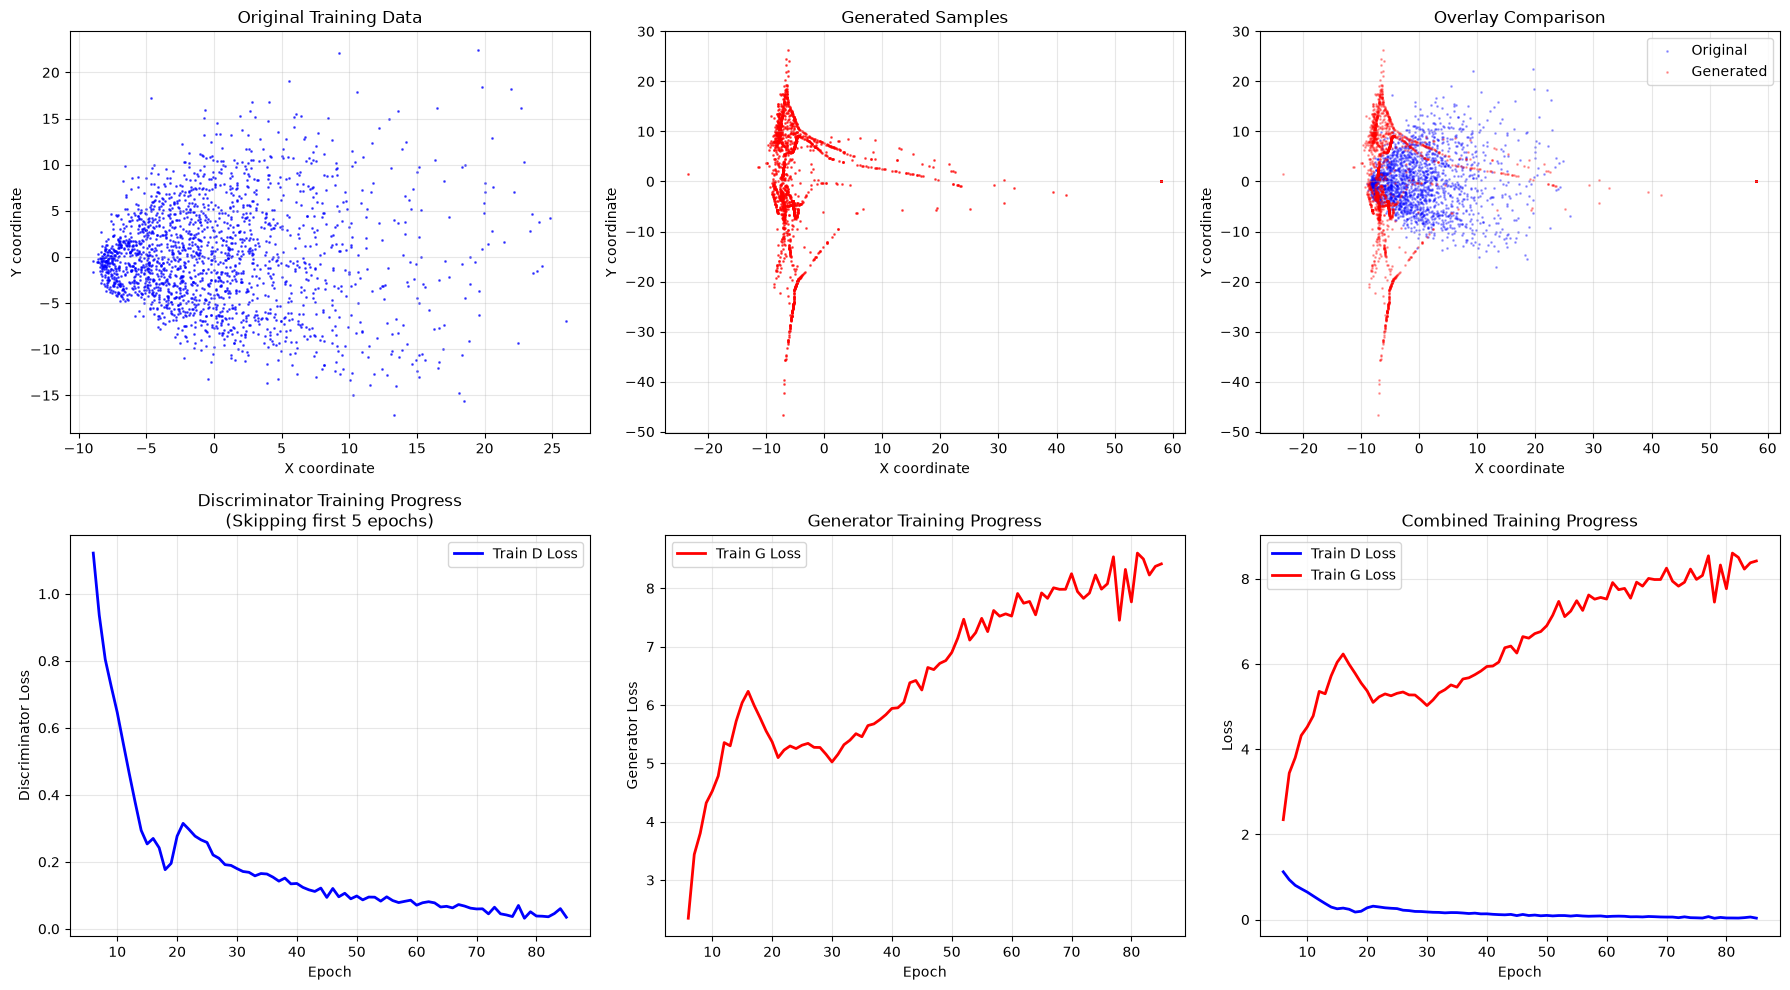

📈 Epoch 85 Summary:
   Train D Loss: 0.0347, Val D Loss: 0.0208
   Train G Loss: 8.4183, Val G Loss: 6.4369

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.015389	G_loss: 6.989900
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.045079	G_loss: 7.126236
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.056678	G_loss: 6.112149
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.009759	G_loss: 7.020195
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.012572	G_loss: 6.367389
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.012570	G_loss: 6.484961
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.034917	G_loss: 9.248026
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.017661	G_loss: 7.227855
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.013927	G_loss: 7.201293
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.014533	G_loss: 6.721241
====> Epoch: 86 Train D_loss: 0.0674, Train G_loss: 8.3910
====> Epoch: 86 Val D_loss: 0.0286, Val G_loss: 5.0800
📈 Epoch 86 Summary:
   Train D Loss: 0.0674, Val D Loss: 0.0286
   Train G Loss: 8.3910

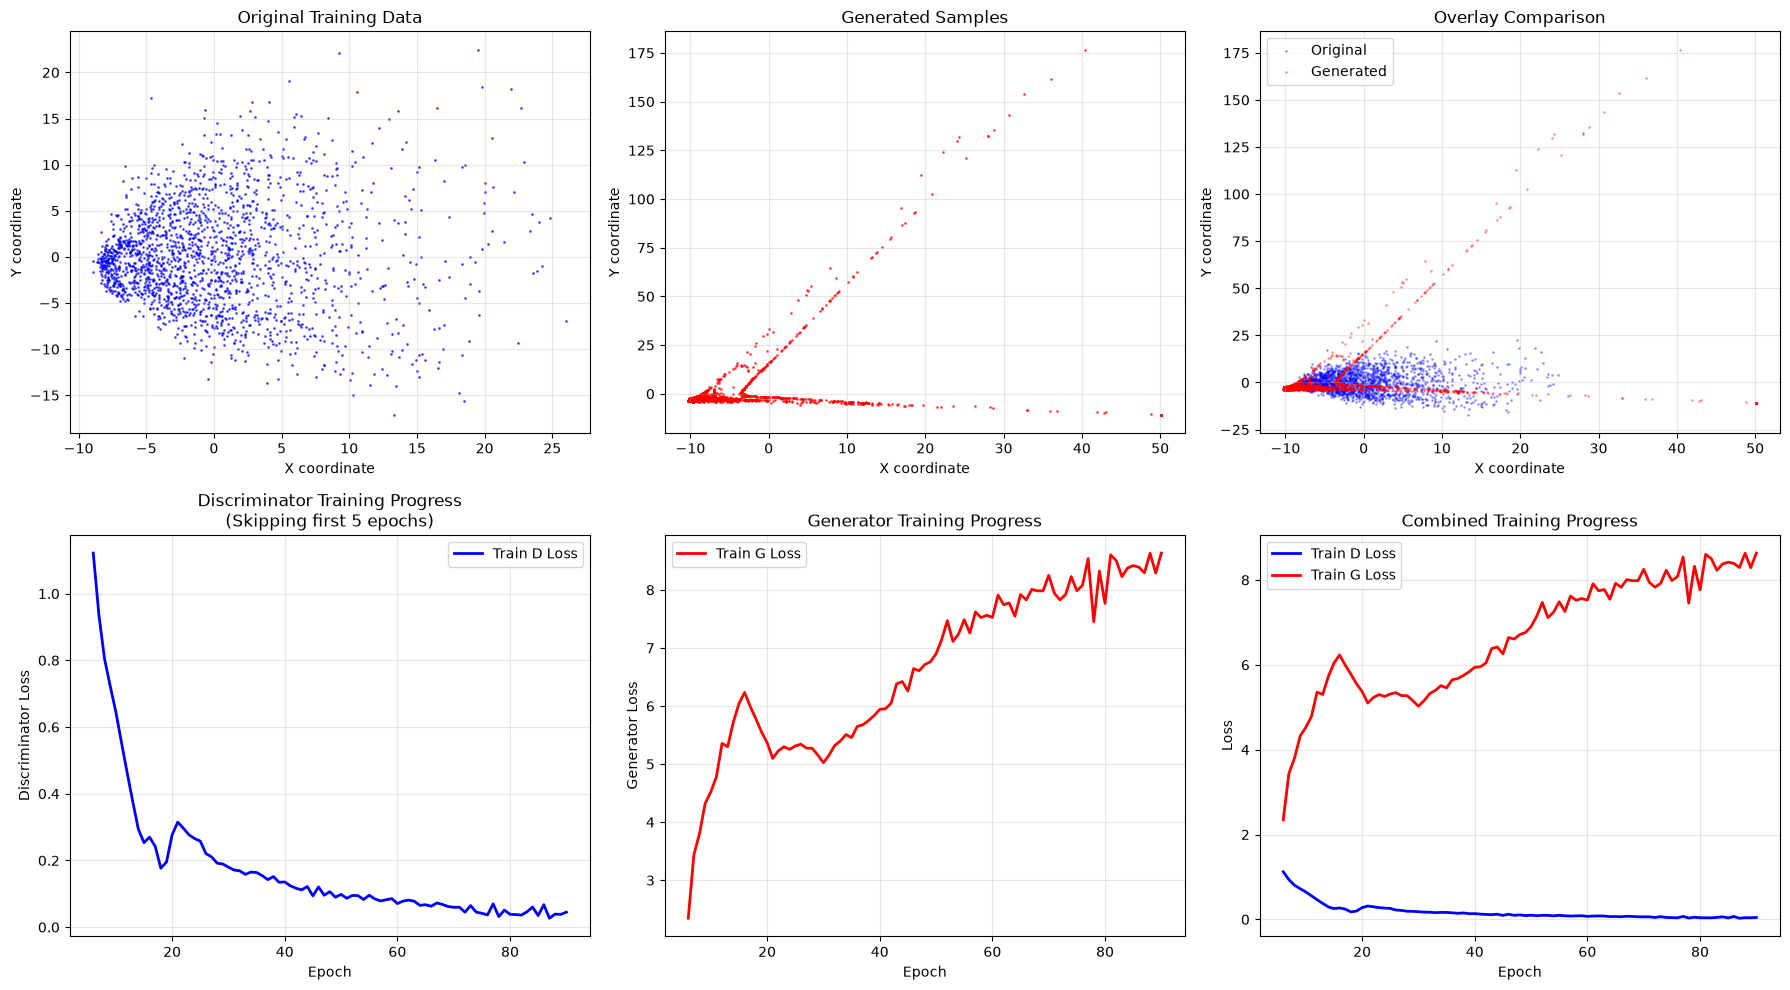

📈 Epoch 90 Summary:
   Train D Loss: 0.0448, Val D Loss: 0.0255
   Train G Loss: 8.6328, Val G Loss: 6.6947

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.007370	G_loss: 7.114817
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.005961	G_loss: 8.212814
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.006766	G_loss: 7.471341
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.021968	G_loss: 8.456490
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.005485	G_loss: 7.262030
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.001597	G_loss: 6.336301
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.011942	G_loss: 8.432949
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.017935	G_loss: 9.729910
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.243651	G_loss: 10.037307
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.025171	G_loss: 9.517135
====> Epoch: 91 Train D_loss: 0.0393, Train G_loss: 9.1033
====> Epoch: 91 Val D_loss: 0.0430, Val G_loss: 7.0743
📈 Epoch 91 Summary:
   Train D Loss: 0.0393, Val D Loss: 0.0430
   Train G Loss: 9.103

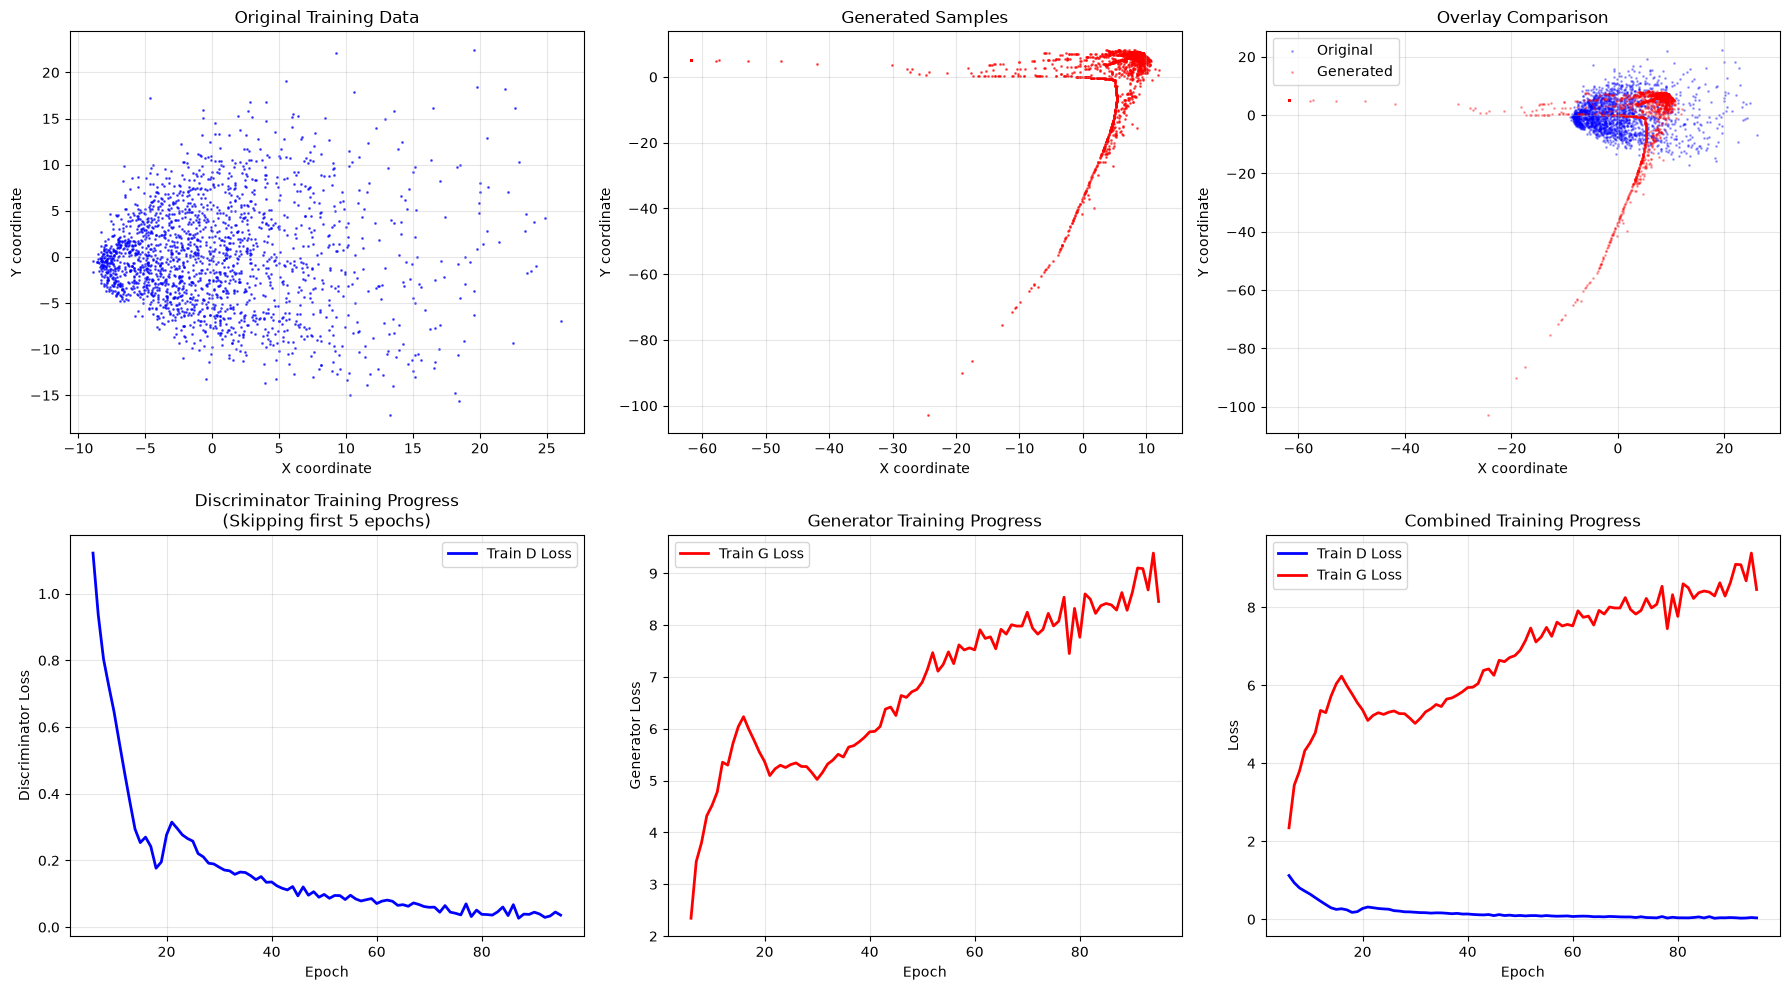

📈 Epoch 95 Summary:
   Train D Loss: 0.0361, Val D Loss: 0.0200
   Train G Loss: 8.4565, Val G Loss: 6.5759

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.010955	G_loss: 7.406157
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.022211	G_loss: 8.684138
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.045582	G_loss: 6.009504
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.004472	G_loss: 10.412646
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.023465	G_loss: 8.237444
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.003460	G_loss: 7.557239
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.002751	G_loss: 8.666475
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.006891	G_loss: 7.247619
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.034275	G_loss: 7.566766
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.018125	G_loss: 9.150227
====> Epoch: 96 Train D_loss: 0.0242, Train G_loss: 9.0686
====> Epoch: 96 Val D_loss: 0.0111, Val G_loss: 8.8167
📈 Epoch 96 Summary:
   Train D Loss: 0.0242, Val D Loss: 0.0111
   Train G Loss: 9.068

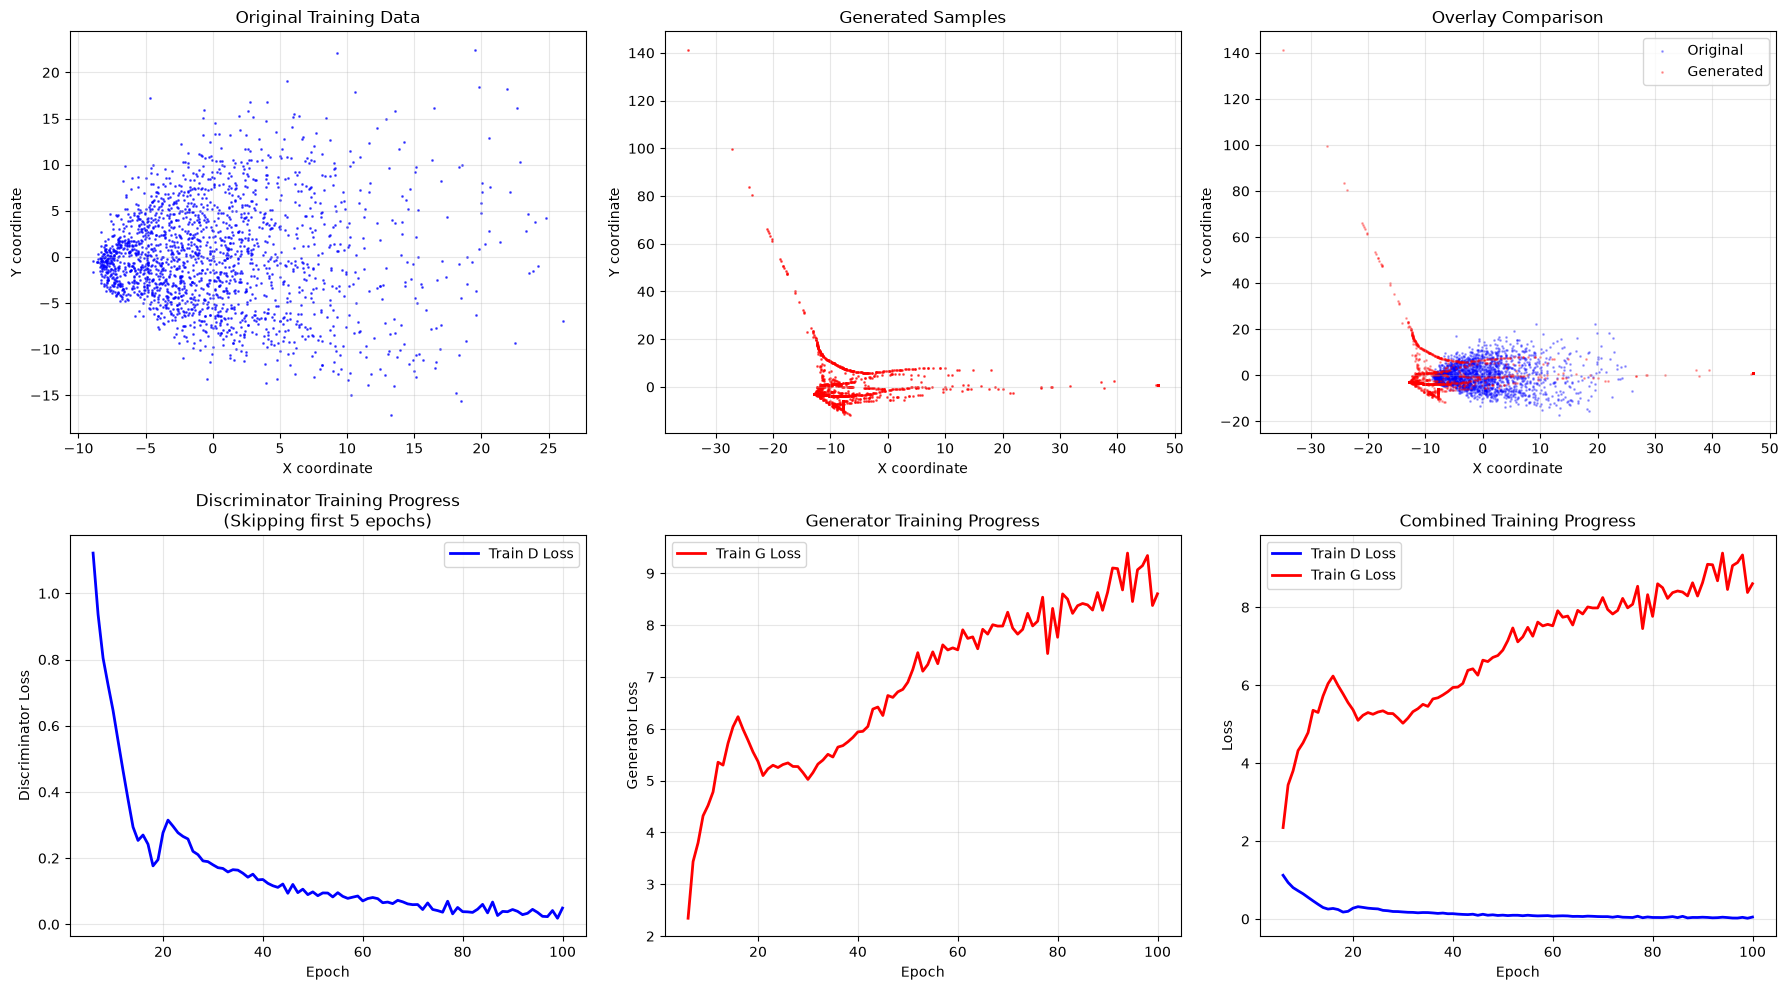

📈 Epoch 100 Summary:
   Train D Loss: 0.0492, Val D Loss: 0.0260
   Train G Loss: 8.6052, Val G Loss: 6.4199

🎉 Training completed!

🎨 Final comprehensive visualization:


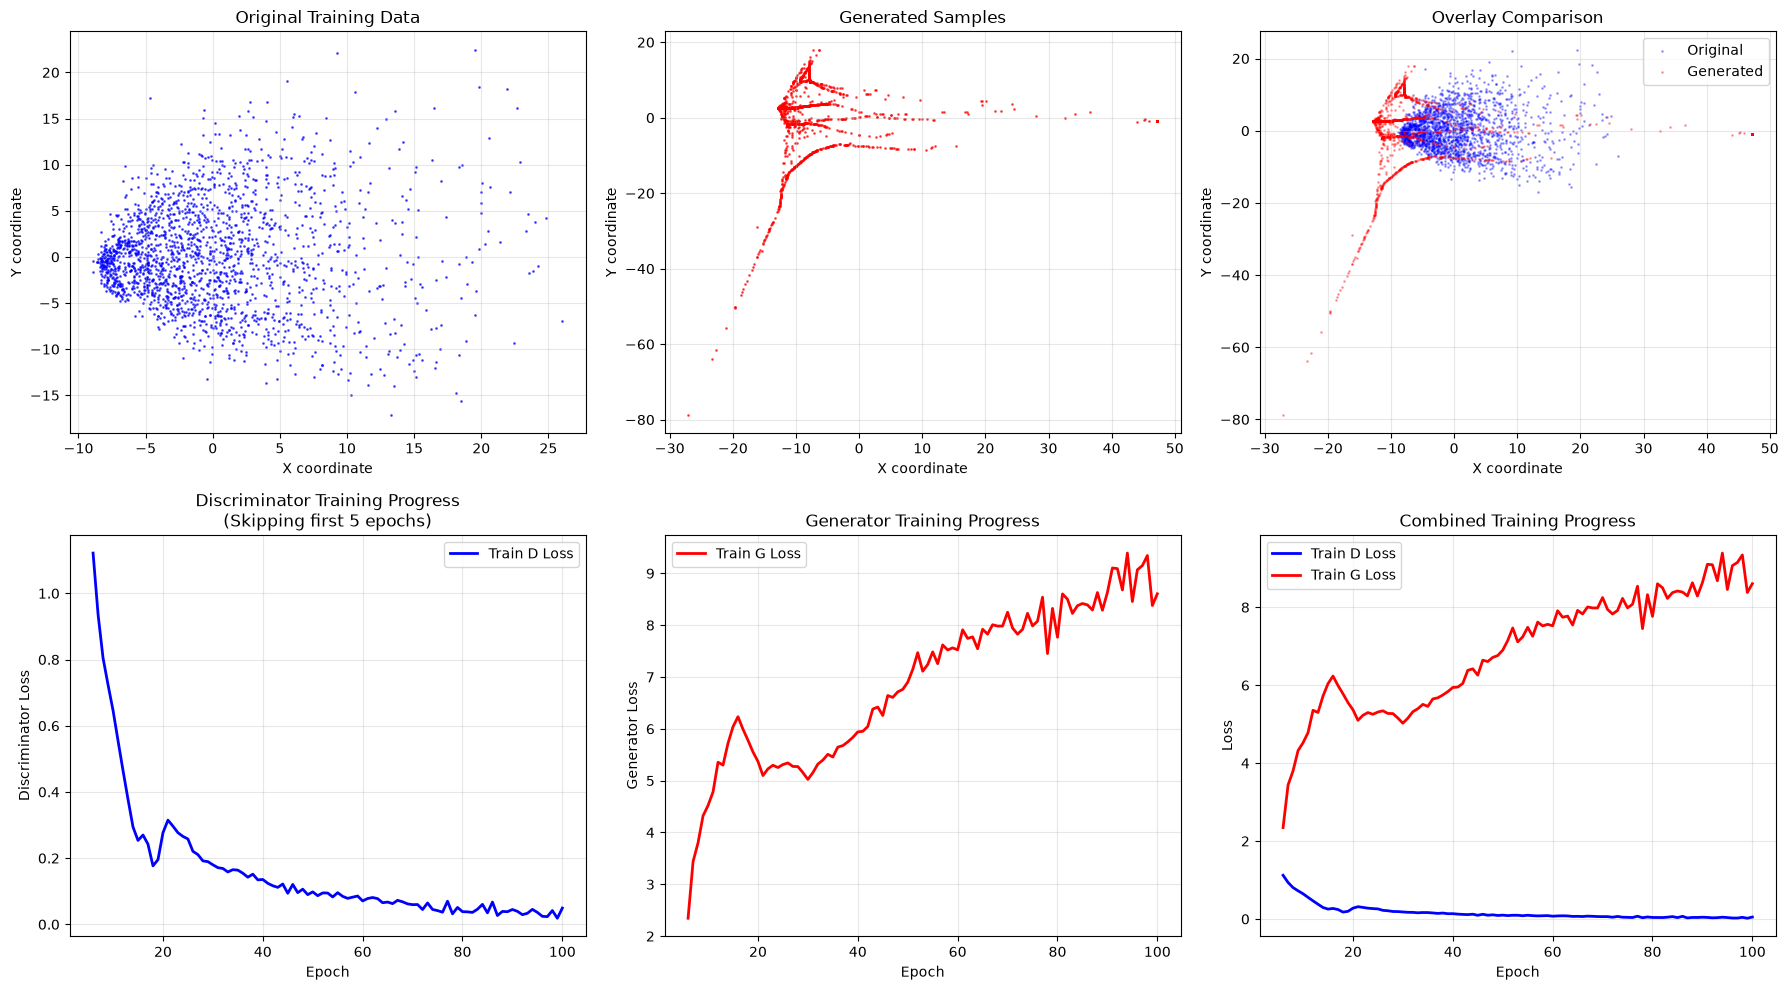

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


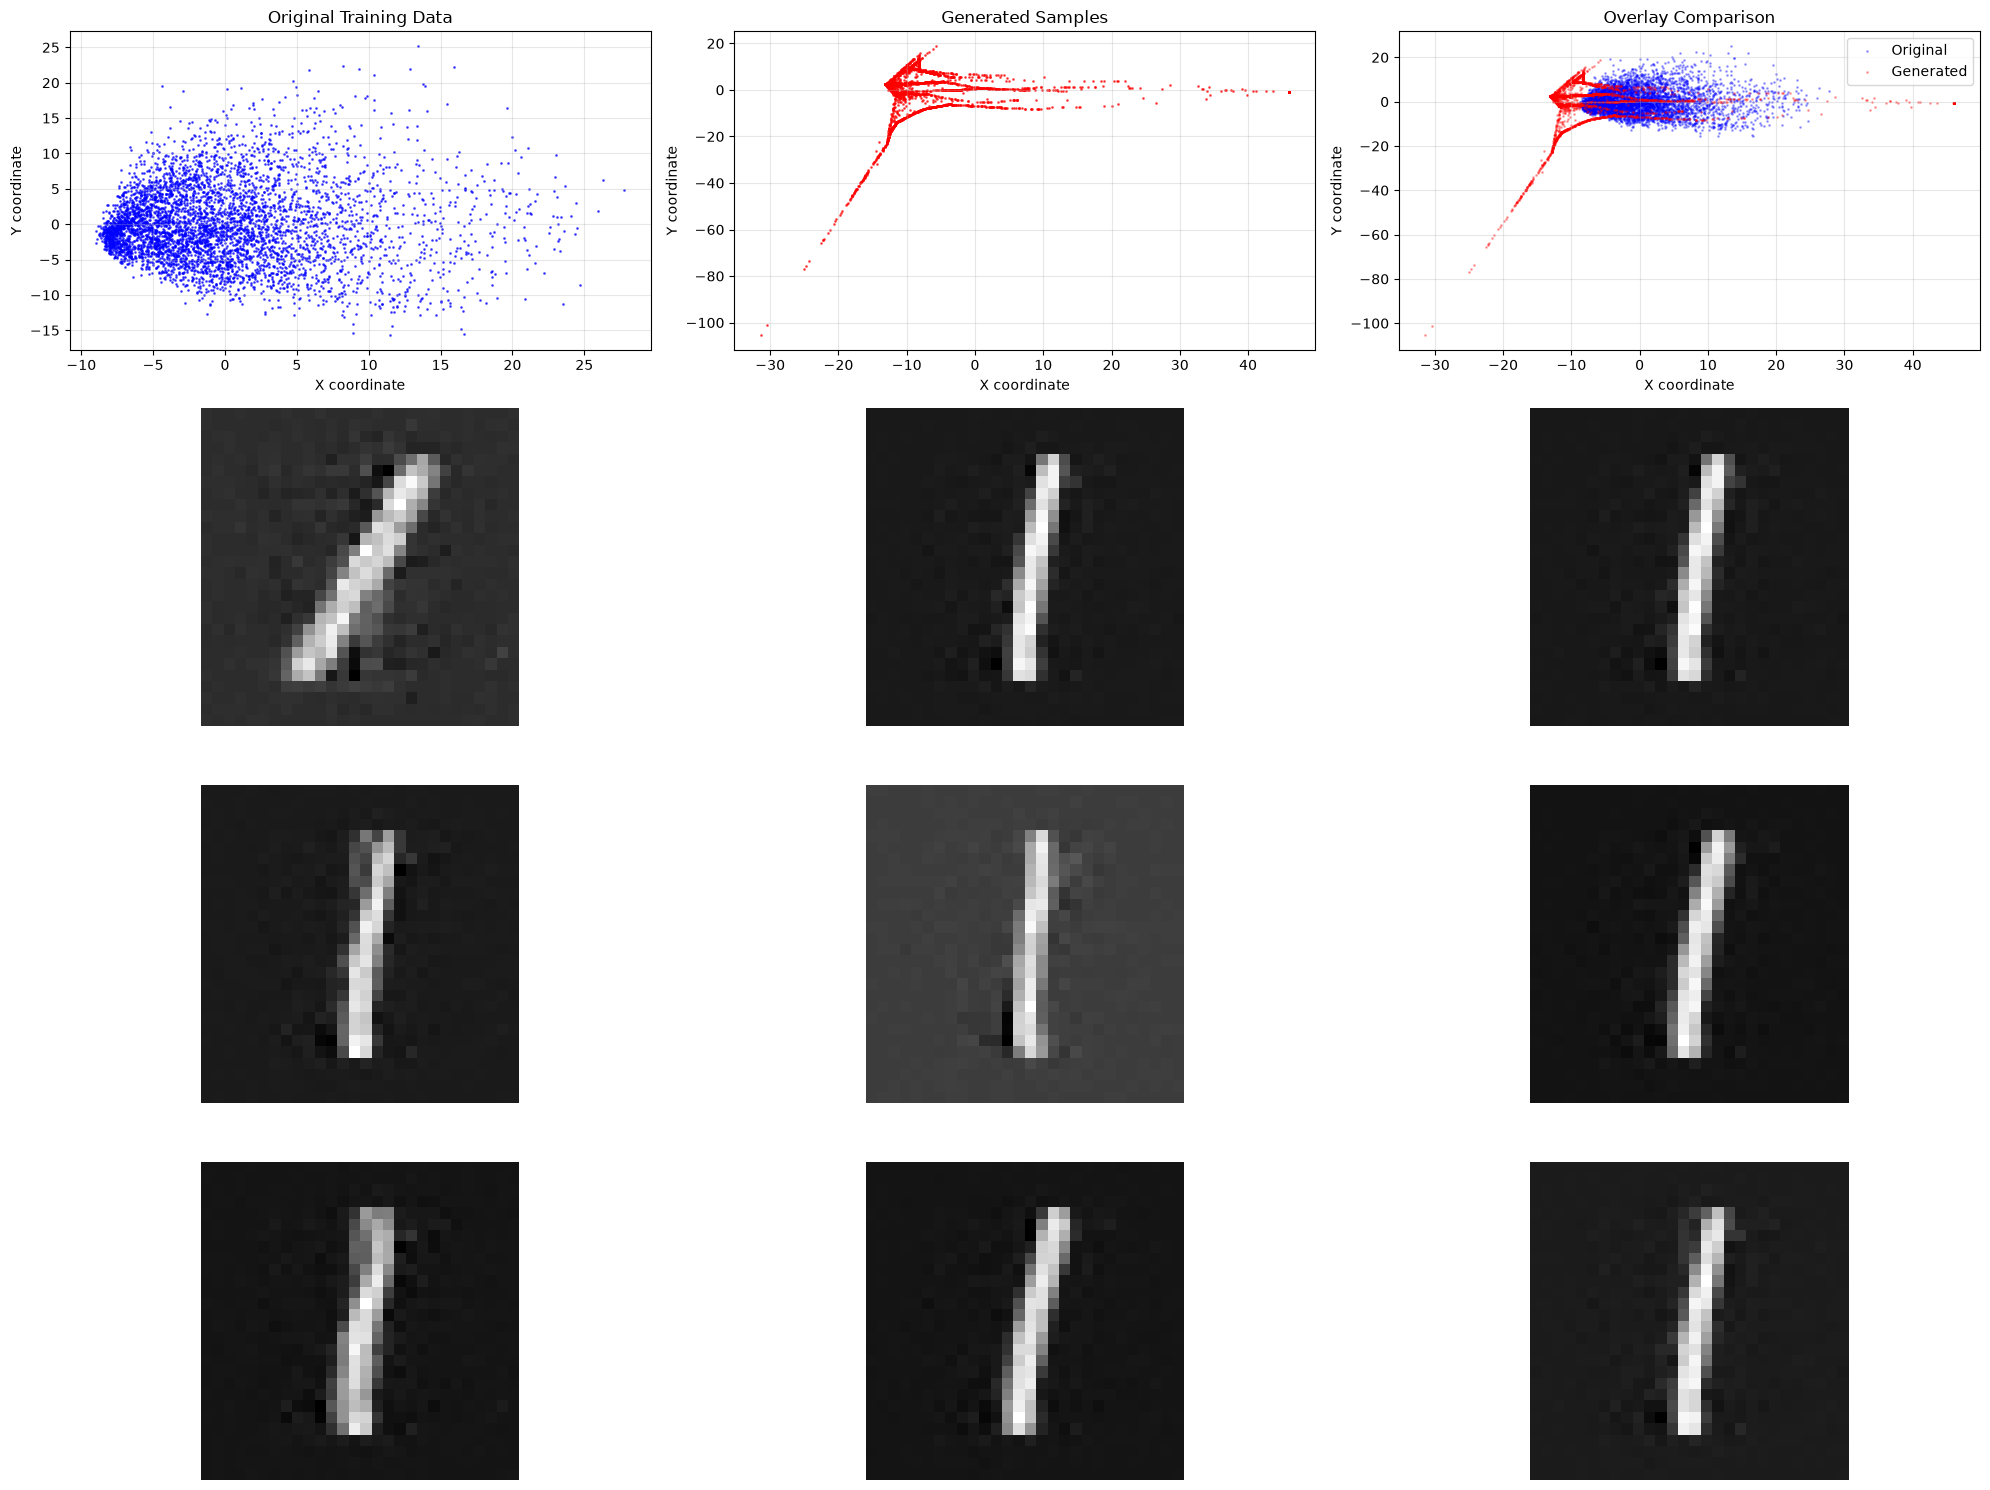

In [20]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()
